# Задание 3.8 — Автоматизация микроскопии


## Загрузка датасета и EDA

In [1]:
import os
import shutil
import subprocess
import sys
import warnings
import xml.etree.ElementTree as ET
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as T
from PIL import Image
from scipy.ndimage import gaussian_filter
from sklearn.covariance import EmpiricalCovariance
from sklearn.metrics import (
    average_precision_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

try:
    from ultralytics import YOLO
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "ultralytics"])
    from ultralytics import YOLO

warnings.filterwarnings("ignore")

import ssl
from urllib.error import URLError


def _ssl_url_problem(exc: BaseException) -> bool:
    msg = str(exc).lower()
    return "certificate" in msg or "cert verify" in msg or "ssl" in msg


def ensure_ssl_for_https_downloads() -> None:
    try:
        import certifi

        ca = certifi.where()
        os.environ.setdefault("SSL_CERT_FILE", ca)
        os.environ.setdefault("REQUESTS_CA_BUNDLE", ca)
    except ImportError:
        pass


def _torch_hub_ssl_fallback() -> None:
    print(
        "Предупреждение: при загрузке весов SSL не прошёл проверку; временно отключена "
        "проверка сертификата (только для локального запуска). На macOS лучше запустить "
        "«Install Certificates.command» из папки Python."
    )
    ssl._create_default_https_context = ssl._create_unverified_context


def load_resnet50_imagenet():
    ensure_ssl_for_https_downloads()
    for attempt in range(2):
        try:
            if hasattr(models, "ResNet50_Weights"):
                return models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
            return models.resnet50(pretrained=True)
        except (URLError, OSError) as e:
            if attempt == 0 and _ssl_url_problem(e):
                _torch_hub_ssl_fallback()
                continue
            raise


ensure_ssl_for_https_downloads()

DATASET_DIR = Path("BCCD_Dataset")  
if not DATASET_DIR.exists():
    subprocess.run(["git", "clone", "https://github.com/Shenggan/BCCD_Dataset.git"], check=True)

IMG_DIR  = DATASET_DIR / "BCCD" / "JPEGImages"
ANN_DIR  = DATASET_DIR / "BCCD" / "Annotations"
SPLIT_DIR = DATASET_DIR / "BCCD" / "ImageSets" / "Main"

for _need in (IMG_DIR, ANN_DIR):
    if not _need.exists():
        raise FileNotFoundError(
            f"Не найдена папка {_need}. Запустите эту ячейку с первой: git clone BCCD_Dataset и проверьте структуру каталогов."
        )
_n_img = len(list(IMG_DIR.glob("*.jpg")))
if _n_img == 0:
    raise FileNotFoundError("В JPEGImages нет *.jpg — датасет не скачан или путь неверный.")

print("Изображений:", _n_img)
print("Аннотаций:",   len(list(ANN_DIR.glob("*.xml"))))


Изображений: 364
Аннотаций: 364


In [2]:
def parse_annotation(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    fname = root.findtext("filename")
    size  = root.find("size")
    if size is None:
        return []
    w_raw, h_raw = size.findtext("width"), size.findtext("height")
    if not w_raw or not h_raw:
        return []
    w, h = int(float(w_raw)), int(float(h_raw))
    records = []
    for obj in root.iter("object"):
        cls = obj.findtext("name")
        bb  = obj.find("bndbox")
        if bb is None:
            continue
        records.append({
            "filename": fname,
            "class":    cls,
            "xmin": int(float(bb.findtext("xmin"))),
            "ymin": int(float(bb.findtext("ymin"))),
            "xmax": int(float(bb.findtext("xmax"))),
            "ymax": int(float(bb.findtext("ymax"))),
            "img_w": w, "img_h": h
        })
    return records

rows = []
for xml_path in sorted(ANN_DIR.glob("*.xml")):
    rows.extend(parse_annotation(xml_path))

df = pd.DataFrame(rows)
df["area"]   = (df["xmax"] - df["xmin"]) * (df["ymax"] - df["ymin"])
df["cx"]     = (df["xmin"] + df["xmax"]) / 2
df["cy"]     = (df["ymin"] + df["ymax"]) / 2
df["aspect"] = (df["xmax"] - df["xmin"]) / (df["ymax"] - df["ymin"]).replace(0, np.nan)

print(df.head())
print("\nКлассы:", df["class"].unique())
print("Всего объектов:", len(df))

               filename class  xmin  ymin  xmax  ymax  img_w  img_h   area  \
0  BloodImage_00000.jpg   WBC   260   177   491   376    640    480  45969   
1  BloodImage_00000.jpg   RBC    78   336   184   435    640    480  10494   
2  BloodImage_00000.jpg   RBC    63   237   169   336    640    480  10494   
3  BloodImage_00000.jpg   RBC   214   362   320   461    640    480  10494   
4  BloodImage_00000.jpg   RBC   414   352   506   445    640    480   8556   

      cx     cy    aspect  
0  375.5  276.5  1.160804  
1  131.0  385.5  1.070707  
2  116.0  286.5  1.070707  
3  267.0  411.5  1.070707  
4  460.0  398.5  0.989247  

Классы: ['WBC' 'RBC' 'Platelets']
Всего объектов: 4888


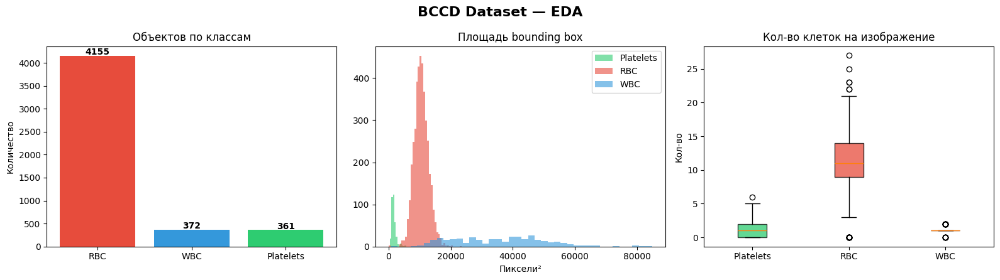

Сохранено: eda_overview.png


In [3]:
CLASS_COLORS = {"RBC": "#e74c3c", "WBC": "#3498db", "Platelets": "#2ecc71"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
fig.suptitle("BCCD Dataset — EDA", fontsize=16, fontweight="bold")

# 1. Количество объектов по классам
ax = axes[0]
counts = df["class"].value_counts()
bars = ax.bar(counts.index, counts.values,
              color=[CLASS_COLORS.get(c, "grey") for c in counts.index])
for bar, v in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
            str(v), ha="center", fontweight="bold")
ax.set_title("Объектов по классам")
ax.set_ylabel("Количество")

# 2. Гистограмма площадей bbox
ax = axes[1]
for cls, grp in df.groupby("class"):
    ax.hist(grp["area"], bins=40, alpha=0.6, label=cls, color=CLASS_COLORS.get(cls))
ax.set_title("Площадь bounding box")
ax.set_xlabel("Пиксели²")
ax.legend()

# 3. Распределение количества клеток на изображение
ax = axes[2]
per_img = df.groupby(["filename", "class"]).size().unstack(fill_value=0)
bp = ax.boxplot([per_img[c].values for c in per_img.columns], patch_artist=True)
ax.set_xticks(range(1, len(per_img.columns) + 1))
ax.set_xticklabels(per_img.columns)
for patch, col in zip(bp["boxes"], per_img.columns):
    patch.set_facecolor(CLASS_COLORS.get(col, "#888888"))
    patch.set_alpha(0.75)
ax.set_title("Кол-во клеток на изображение")
ax.set_ylabel("Кол-во")

plt.tight_layout()
plt.savefig("eda_overview.png", dpi=120)
plt.show()
print("Сохранено: eda_overview.png")

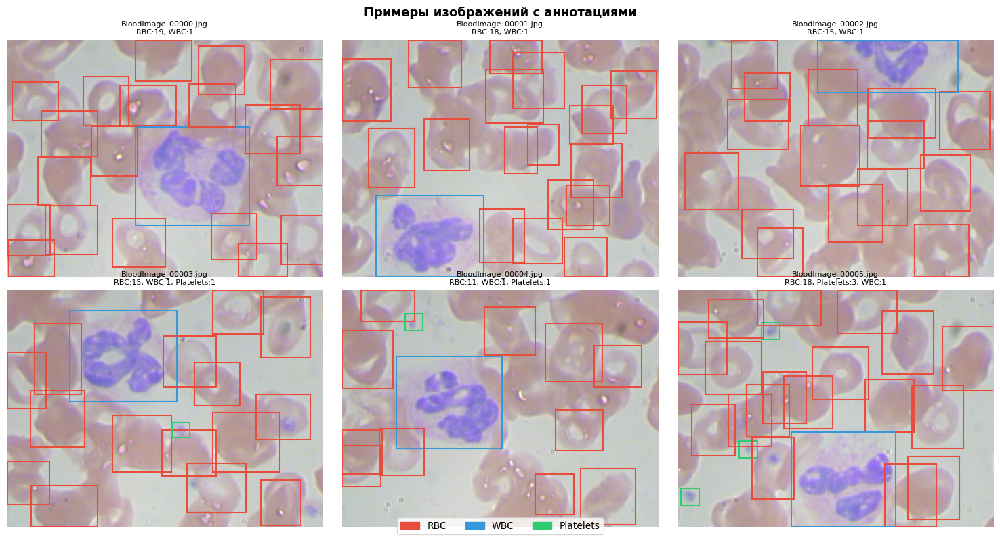

In [4]:
sample_files = sorted(IMG_DIR.glob("*.jpg"))[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, img_path in zip(axes.flat, sample_files):
    img = Image.open(img_path)
    ax.imshow(img)
    fname = img_path.name
    sub = df[df["filename"] == fname]
    for _, row in sub.iterrows():
        color = CLASS_COLORS.get(row["class"], "white")
        rect  = patches.Rectangle(
            (row["xmin"], row["ymin"]),
            row["xmax"] - row["xmin"], row["ymax"] - row["ymin"],
            linewidth=1.5, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
    counts_str = ", ".join(f"{c}:{n}" for c, n in
                           sub["class"].value_counts().items())
    ax.set_title(f"{fname}\n{counts_str}", fontsize=8)
    ax.axis("off")

handles = [patches.Patch(color=v, label=k) for k, v in CLASS_COLORS.items()]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=10)
plt.suptitle("Примеры изображений с аннотациями", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("sample_images.png", dpi=120)
plt.show()

## 2. ResNet regression: подсчёт клеток (ResNet50)


In [5]:
DEVICE = (
    "mps"  if torch.backends.mps.is_available() else
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", DEVICE)

Device: mps


In [6]:
CLASSES = ["RBC", "WBC", "Platelets"]

per_img = df.groupby("filename")["class"].value_counts().unstack(fill_value=0)
for cls in CLASSES:
    if cls not in per_img.columns:
        per_img[cls] = 0
per_img = per_img[CLASSES].reset_index()

per_img = per_img[per_img["filename"].apply(lambda f: (IMG_DIR / f).exists())].reset_index(drop=True)  # оставляем только существующие файлы

print(per_img.head())
print("\nСтатистика:")
print(per_img[CLASSES].describe().round(1))

class              filename  RBC  WBC  Platelets
0      BloodImage_00000.jpg   19    1          0
1      BloodImage_00001.jpg   18    1          0
2      BloodImage_00002.jpg   15    1          0
3      BloodImage_00003.jpg   15    1          1
4      BloodImage_00004.jpg   11    1          1

Статистика:
class    RBC    WBC  Platelets
count  364.0  364.0      364.0
mean    11.4    1.0        1.0
std      4.3    0.2        1.2
min      0.0    0.0        0.0
25%      9.0    1.0        0.0
50%     11.0    1.0        1.0
75%     14.0    1.0        2.0
max     27.0    2.0        6.0


In [7]:
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

train_tf = T.Compose([
    T.Resize((256, 256)),
    T.RandomCrop(224),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
    T.RandomRotation(15),
    T.ToTensor(),
    T.Normalize(MEAN, STD)
])
val_tf = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(MEAN, STD)
])

class BCCDRegressionDataset(Dataset):
    def __init__(self, records, img_dir, transform):
        self.records  = records.reset_index(drop=True)
        self.img_dir  = Path(img_dir)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        row   = self.records.iloc[idx]
        img   = Image.open(self.img_dir / row["filename"]).convert("RGB")
        img   = self.transform(img)
        label = torch.tensor(row[CLASSES].values.astype(float), dtype=torch.float32)
        return img, label

train_df, val_df = train_test_split(per_img, test_size=0.2, random_state=42)
train_ds = BCCDRegressionDataset(train_df, IMG_DIR, train_tf)
val_ds   = BCCDRegressionDataset(val_df,   IMG_DIR, val_tf)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=16, shuffle=False, num_workers=0)
print(f"Train: {len(train_ds)}, Val: {len(val_ds)}")


Train: 291, Val: 73


In [8]:
def build_regression_model(n_outputs=3, freeze_backbone=True):
    model = load_resnet50_imagenet()
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Linear(in_features, 256),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(256, n_outputs),
        nn.ReLU()  # количество клеток >= 0
    )
    return model

model_reg = build_regression_model().to(DEVICE)

optimizer = torch.optim.Adam(model_reg.fc.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.5)
criterion = nn.SmoothL1Loss()  # устойчив к выбросам


def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(imgs)
    return total_loss / len(loader.dataset)


@torch.no_grad()
def eval_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    preds, targets = [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        out = model(imgs)
        loss = criterion(out, labels)
        total_loss += loss.item() * len(imgs)
        preds.append(out.cpu().numpy())
        targets.append(labels.cpu().numpy())
    preds = np.concatenate(preds)
    targets = np.concatenate(targets)
    return total_loss / len(loader.dataset), preds, targets


total_params = sum(p.numel() for p in model_reg.parameters() if p.requires_grad)
print(f"Обучаемых параметров: {total_params:,}")

Обучаемых параметров: 525,315


In [9]:
CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESNET_CKPT_HEAD = CHECKPOINT_DIR / "resnet_bccd_count.pt"
RESNET_CKPT_FT = CHECKPOINT_DIR / "resnet_bccd_finetuned.pt"

EPOCHS_HEAD = 15
EPOCHS_FT = 15

history = {
    "stage1_train_loss": [],
    "stage1_val_loss": [],
    "stage2_train_loss": [],
    "stage2_val_loss": [],
}

def _normalize_history(hist):
    hist = dict(hist) if isinstance(hist, dict) else {}
    hist.setdefault("stage1_train_loss", hist.get("train_loss", []))
    hist.setdefault("stage1_val_loss", hist.get("val_loss", []))
    hist.setdefault("stage2_train_loss", [])
    hist.setdefault("stage2_val_loss", [])
    return hist

_loaded_finetuned = False
_stage1_ready = False

if RESNET_CKPT_FT.exists():
    try:
        try:
            ckpt = torch.load(RESNET_CKPT_FT, map_location=DEVICE, weights_only=False)
        except TypeError:
            ckpt = torch.load(RESNET_CKPT_FT, map_location=DEVICE)
        model_reg.load_state_dict(ckpt["model"])
        history = _normalize_history(ckpt.get("history", history))
        print(
            f"Загружен финальный чекпойнт ResNet: {RESNET_CKPT_FT.resolve()} "
            f"(head_epochs={ckpt.get('head_epochs', '?')}, ft_epochs={ckpt.get('ft_epochs', '?')})."
        )
        _loaded_finetuned = True
    except Exception as e:
        print(f"Финальный чекпойнт не удалось загрузить ({e}), запускаем обучение заново.")

if not _loaded_finetuned and RESNET_CKPT_HEAD.exists():
    try:
        try:
            ckpt_head = torch.load(RESNET_CKPT_HEAD, map_location=DEVICE, weights_only=False)
        except TypeError:
            ckpt_head = torch.load(RESNET_CKPT_HEAD, map_location=DEVICE)
        model_reg.load_state_dict(ckpt_head["model"])
        optimizer.load_state_dict(ckpt_head["optimizer"])
        scheduler.load_state_dict(ckpt_head["scheduler"])
        history = _normalize_history(ckpt_head.get("history", history))
        _stage1_ready = True
        print(
            f"Загружен чекпойнт этапа 1: {RESNET_CKPT_HEAD.resolve()}. "
            "Переходим сразу к fine-tuning layer4."
        )
    except Exception as e:
        print(f"Чекпойнт этапа 1 не удалось загрузить ({e}), выполняем оба этапа.")

if not _loaded_finetuned and not _stage1_ready:
    for epoch in range(1, EPOCHS_HEAD + 1):
        tr_loss = train_epoch(model_reg, train_loader, optimizer, criterion, DEVICE)
        vl_loss, preds, targets = eval_epoch(model_reg, val_loader, criterion, DEVICE)
        scheduler.step()

        history["stage1_train_loss"].append(tr_loss)
        history["stage1_val_loss"].append(vl_loss)

        if epoch % 5 == 0 or epoch == 1:
            mae_per = [mean_absolute_error(targets[:, i], preds[:, i]) for i in range(3)]
            print(f"Head Epoch {epoch:2d}/{EPOCHS_HEAD} | tr_loss={tr_loss:.3f} | val_loss={vl_loss:.3f}"
                  f" | MAE RBC={mae_per[0]:.1f} WBC={mae_per[1]:.2f} Plt={mae_per[2]:.2f}")

    torch.save(
        {
            "model": model_reg.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "history": history,
            "epochs_trained": EPOCHS_HEAD,
        },
        RESNET_CKPT_HEAD,
    )
    _stage1_ready = True
    print(f"Чекпойнт этапа 1 сохранён: {RESNET_CKPT_HEAD.resolve()}")

if not _loaded_finetuned:
    for name, param in model_reg.named_parameters():  # fine-tuning размораживает layer4 и fc
        if "layer4" in name or "fc" in name:
            param.requires_grad = True

    optimizer_ft = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model_reg.parameters()),
        lr=1e-4,
        weight_decay=1e-4,
    )
    scheduler_ft = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_ft, T_max=EPOCHS_FT)

    for epoch in range(1, EPOCHS_FT + 1):
        tr_loss = train_epoch(model_reg, train_loader, optimizer_ft, criterion, DEVICE)
        vl_loss, preds, targets = eval_epoch(model_reg, val_loader, criterion, DEVICE)
        scheduler_ft.step()

        history["stage2_train_loss"].append(tr_loss)
        history["stage2_val_loss"].append(vl_loss)

        if epoch % 5 == 0 or epoch == 1:
            mae_per = [mean_absolute_error(targets[:, i], preds[:, i]) for i in range(3)]
            print(f"FT Epoch {epoch:2d}/{EPOCHS_FT} | tr={tr_loss:.3f} | val={vl_loss:.3f}"
                  f" | MAE RBC={mae_per[0]:.1f} WBC={mae_per[1]:.2f} Plt={mae_per[2]:.2f}")

    torch.save(
        {
            "model": model_reg.state_dict(),
            "optimizer_ft": optimizer_ft.state_dict(),
            "scheduler_ft": scheduler_ft.state_dict(),
            "history": history,
            "head_epochs": EPOCHS_HEAD,
            "ft_epochs": EPOCHS_FT,
        },
        RESNET_CKPT_FT,
    )
    print(f"Чекпойнт fine-tuning сохранён: {RESNET_CKPT_FT.resolve()}")


Загружен финальный чекпойнт ResNet: /Users/arseniy/Documents/Машинное обучение/checkpoints/resnet_bccd_finetuned.pt (head_epochs=15, ft_epochs=15).


In [10]:
_, preds, targets = eval_epoch(model_reg, val_loader, criterion, DEVICE)
preds_rounded = np.round(preds).clip(0)

is_finetuned = len(history.get("stage2_train_loss", [])) > 0
model_stage = "fine-tuned (head + layer4)" if is_finetuned else "head-only"
print(f"Текущая модель: {model_stage}")

print("=" * 65)
print(f"{'Класс':12} {'MAE':>8} {'RMSE':>8} {'MAE_int':>9} {'R²':>8}")
print("-" * 65)
for i, cls in enumerate(CLASSES):
    mae = mean_absolute_error(targets[:, i], preds[:, i])
    rmse = np.sqrt(mean_squared_error(targets[:, i], preds[:, i]))
    mae_i = mean_absolute_error(targets[:, i], preds_rounded[:, i])
    r2 = r2_score(targets[:, i], preds[:, i])
    print(f"{cls:12} {mae:8.2f} {rmse:8.2f} {mae_i:9.2f} {r2:8.3f}")
print("=" * 65)

exact_match = np.all(preds_rounded == targets, axis=1).mean()
print(f"Exact match (все 3 класса):  {exact_match:.1%}")

total_pred = preds_rounded.sum(axis=1)
total_target = targets.sum(axis=1)
mae_total = mean_absolute_error(total_target, total_pred)
print(f"MAE (суммарное кол-во):      {mae_total:.2f}")


Текущая модель: fine-tuned (head + layer4)
Класс             MAE     RMSE   MAE_int       R²
-----------------------------------------------------------------
RBC              2.62     3.51      2.56    0.252
WBC              0.15     0.24      0.04   -0.440
Platelets        1.06     1.43      1.03   -0.167
Exact match (все 3 класса):  5.5%
MAE (суммарное кол-во):      3.08


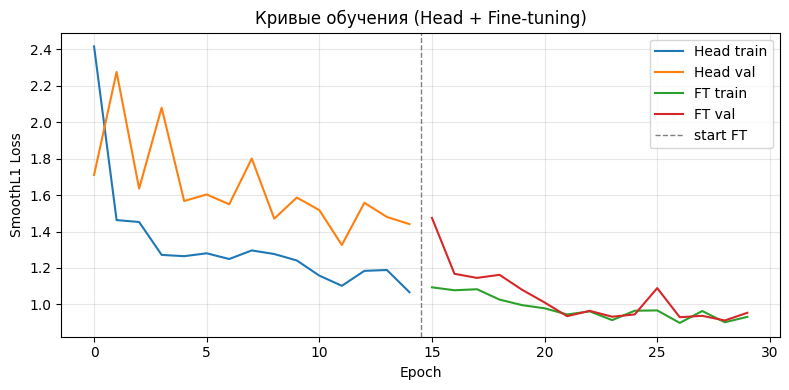

In [11]:
# Кривые обучения
try:
    plt.figure(figsize=(8, 4))

    if len(history.get("stage1_train_loss", [])) > 0:
        x1 = range(len(history["stage1_train_loss"]))
        plt.plot(x1, history["stage1_train_loss"], label="Head train")
        plt.plot(x1, history["stage1_val_loss"], label="Head val")

    if len(history.get("stage2_train_loss", [])) > 0:
        offset = len(history.get("stage1_train_loss", []))
        x2 = range(offset, offset + len(history["stage2_train_loss"]))
        plt.plot(x2, history["stage2_train_loss"], label="FT train")
        plt.plot(x2, history["stage2_val_loss"], label="FT val")
        plt.axvline(offset - 0.5, color="grey", linestyle="--", linewidth=1, label="start FT")

    plt.xlabel("Epoch")
    plt.ylabel("SmoothL1 Loss")
    plt.title("Кривые обучения (Head + Fine-tuning)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("loss_curves.png", dpi=120)
    plt.show()
except NameError:
    print("Кривые обучения пропущены: выполните ячейку с циклом обучения (переменная history).")


## 3. YOLO: подсчёт через детекцию (YOLOv8)


In [12]:

YOLO_DIR  = Path("yolo_bccd")
CLASS_MAP = {"RBC": 0, "WBC": 1, "Platelets": 2}


def prepare_yolo_bccd_dataset(*, silent: bool = False) -> None:
    for split in ["train", "val"]:
        (YOLO_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
        (YOLO_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

    all_fnames = list(IMG_DIR.glob("*.jpg"))
    train_files, val_files = train_test_split(all_fnames, test_size=0.2, random_state=42)

    def convert_to_yolo(xml_path, img_dir, out_label_dir):
        records = parse_annotation(xml_path)
        if not records:
            return
        w, h = records[0]["img_w"], records[0]["img_h"]
        out_lines = []
        for r in records:
            if r["class"] not in CLASS_MAP:
                continue
            cls_id = CLASS_MAP[r["class"]]
            cx = ((r["xmin"] + r["xmax"]) / 2) / w
            cy = ((r["ymin"] + r["ymax"]) / 2) / h
            bw = (r["xmax"] - r["xmin"]) / w
            bh = (r["ymax"] - r["ymin"]) / h
            out_lines.append(f"{cls_id} {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}")
        label_file = Path(out_label_dir) / (xml_path.stem + ".txt")
        label_file.write_text("\n".join(out_lines))

    for split, files in [("train", train_files), ("val", val_files)]:
        for img_path in files:
            shutil.copy(img_path, YOLO_DIR / "images" / split / img_path.name)
            xml_path = ANN_DIR / (img_path.stem + ".xml")
            if xml_path.exists():
                convert_to_yolo(xml_path, IMG_DIR, YOLO_DIR / "labels" / split)

    yaml_content = f"""path: {YOLO_DIR.resolve()}
train: images/train
val: images/val
nc: 3
names: ['RBC', 'WBC', 'Platelets']
"""
    (YOLO_DIR / "dataset.yaml").write_text(yaml_content)
    if not silent:
        print("YOLO dataset готов")
        print(f"Train: {len(train_files)}, Val: {len(val_files)}")


prepare_yolo_bccd_dataset()

YOLO dataset готов
Train: 291, Val: 73


In [13]:

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
YOLO_CKPT = CHECKPOINT_DIR / "yolo_bccd_best.pt"

yolo_model = YOLO("yolov8n.pt")  
                                  
_train_device = "cpu" if DEVICE == "mps" else DEVICE
if DEVICE == "mps":
    print("YOLO train: DEVICE=mps → используем CPU для обучения (совместимость ultralytics).")

if not (YOLO_DIR / "dataset.yaml").exists():
    prepare_yolo_bccd_dataset(silent=True)
    print("датасет пересоздан")

_skipped_yolo = False
if YOLO_CKPT.exists():
    print(
        f"Найден сохранённый чекпойнт YOLO ({YOLO_CKPT.resolve()}) — обучение пропущено.\n"
        "Чтобы переобучить — удалите этот файл."
    )
    _skipped_yolo = True

if not _skipped_yolo:
    try:
        results = yolo_model.train(
            data    = str(YOLO_DIR / "dataset.yaml"),
            epochs  = 30,
            imgsz   = 640,
            batch   = 8,
            device  = _train_device,
            name    = "bccd_yolo",
            project = "yolo_runs",
            patience= 10,
            verbose = False
        )
    except Exception as e:
        raise RuntimeError(
            "Ошибка обучения YOLO. Проверьте: веса yolov8n.pt (интернет/SSL), dataset.yaml, зависимости ultralytics. "
            f"Исходная ошибка: {e}"
        ) from e

    # Копируем свежий best.pt в checkpoints (последний по времени под runs/detect)
    candidates = sorted(
        Path(".").glob("runs/detect/**/weights/best.pt"),
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )
    if candidates:
        shutil.copy2(candidates[0], YOLO_CKPT)
        print(f"Лучшие веса YOLO скопированы в {YOLO_CKPT.resolve()} (из {candidates[0]})")

_wdir = Path("runs/detect/yolo_runs/bccd_yolo/weights").resolve()
print(f"Ожидаемый каталог весов после успешного обучения: {_wdir}")

YOLO train: DEVICE=mps → используем CPU для обучения (совместимость ultralytics).
Найден сохранённый чекпойнт YOLO (/Users/arseniy/Documents/Машинное обучение/checkpoints/yolo_bccd_best.pt) — обучение пропущено.
Чтобы переобучить — удалите этот файл.
Ожидаемый каталог весов после успешного обучения: /Users/arseniy/Documents/Машинное обучение/runs/detect/yolo_runs/bccd_yolo/weights


In [14]:

def _find_yolo_weights(name: str) -> list:
    bases = [Path.cwd().resolve()]
    p = Path.cwd().resolve()
    for _ in range(4):
        p = p.parent
        bases.append(p)

    seen, out = set(), []
    priority = []
    if name == "best":
        for root in bases:
            try:
                cp = (root / "checkpoints" / "yolo_bccd_best.pt").resolve()
            except OSError:
                continue
            if cp.is_file() and cp not in seen:
                seen.add(cp)
                priority.append(cp)

    for root in bases:
        candidates = [
            root / "runs/detect/yolo_runs/bccd_yolo/weights" / f"{name}.pt",
            root / "yolo_runs/bccd_yolo/weights" / f"{name}.pt",
        ]
        rd = root / "runs/detect/yolo_runs"
        if rd.is_dir():
            for d in sorted(rd.glob("bccd_yolo*")):
                candidates.append(d / "weights" / f"{name}.pt")
        for path in candidates:
            try:
                path = path.resolve()
                if path in seen or not path.is_file():
                    continue
                seen.add(path)
                out.append(path)
            except OSError:
                continue

    globs = (
        "yolo_runs/**/weights/*.pt",
        "runs/detect/**/weights/*.pt",
        "runs/**/weights/*.pt",
    )
    for root in bases:
        for g in globs:
            for path in root.glob(g):
                if path.name != f"{name}.pt":
                    continue
                try:
                    key = path.resolve()
                except OSError:
                    continue
                if key in seen or not path.is_file():
                    continue
                seen.add(key)
                out.append(path)

    out.sort(key=lambda x: x.stat().st_mtime, reverse=True)
    if name == "best" and priority:
        return priority + out
    return out


best_weights = _find_yolo_weights("best")
last_weights = _find_yolo_weights("last")

if best_weights:
    wpath = best_weights[0]
elif last_weights:
    wpath = last_weights[0]
    print("Используется last.pt (best.pt не найден):", wpath.resolve())
else:
    wpath = "yolov8n.pt"
    print(
        "Обученные веса не найдены (ожидали runs/detect/yolo_runs/bccd_yolo*/weights/*.pt).\n"
        f"Текущая рабочая папка: {Path.cwd().resolve()}\n"
        "Загружается предобученный yolov8n.pt — метрики на BCCD будут условными."
    )

yolo_best = YOLO(str(wpath))
print("Загружена модель:", wpath)

Загружена модель: /Users/arseniy/Documents/Машинное обучение/checkpoints/yolo_bccd_best.pt


In [15]:
val_metrics = yolo_best.val(
    data=str(YOLO_DIR / "dataset.yaml"),
    conf=0.25,
    iou=0.5,
    verbose=False,
)

box_metrics = getattr(val_metrics, "box", None)
if box_metrics is None:
    print("Метрики box недоступны в текущей версии Ultralytics.")
else:
    mp = getattr(box_metrics, "mp", float("nan"))
    mr = getattr(box_metrics, "mr", float("nan"))
    map50 = getattr(box_metrics, "map50", float("nan"))
    map50_95 = getattr(box_metrics, "map", float("nan"))
    per_class = getattr(box_metrics, "maps", None)

    print("=" * 50)
    print(f"{'Метрика':<20} {'Значение':>10}")
    print("-" * 50)
    print(f"{'mAP@0.50':<20} {map50:>10.3f}")
    print(f"{'mAP@0.50:0.95':<20} {map50_95:>10.3f}")
    print(f"{'Precision (mean)':<20} {mp:>10.3f}")
    print(f"{'Recall (mean)':<20} {mr:>10.3f}")
    print("=" * 50)

    if per_class is not None:
        print("\nmAP@0.5:0.95 по классам:")
        for cls, v in zip(CLASSES, per_class):
            print(f"  {cls:<12} {v:.3f}")


Ultralytics 8.4.47 🚀 Python-3.12.0 torch-2.11.0 CPU (Apple M1 Pro)
Model summary (fused): 73 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 465.1±153.1 MB/s, size: 20.5 KB)
val: Scanning /Users/arseniy/Documents/Машинное обучение/yolo_bccd/labels/val.cache... 73 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 73/73 14.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.1s/it 10.5s3.3s
                   all         73        990      0.863      0.912      0.886      0.632
Speed: 1.3ms preprocess, 132.4ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /Users/arseniy/Documents/Машинное обучение/runs/detect/val-18
Метрика                Значение
--------------------------------------------------
mAP@0.50                  0.886
mAP@0.50:0.95             0.632
Precision (mean)          0.863
Recall (mean)             0.912

mAP@0.5:0.95 

**Что это даёт.** mAP — основная детекционная метрика YOLO, учитывающая и локализацию, и классификацию. Precision/Recall помогают понять, модель чаще пропускает объекты или делает лишние срабатывания.


In [16]:
# Запускаем инференс на val-изображениях и считаем клетки
CLASS_IDX = {0: "RBC", 1: "WBC", 2: "Platelets"}

detection_results = []
for img_path in (YOLO_DIR / "images" / "val").glob("*.jpg"):
    r = yolo_best.predict(str(img_path), conf=0.25, verbose=False)[0]
    counts = {cls: 0 for cls in CLASSES}
    if r.boxes is not None:
        for cls_id in r.boxes.cls.cpu().numpy().astype(int):
            counts[CLASS_IDX[cls_id]] += 1
    detection_results.append({"filename": img_path.name, **counts})

det_df = pd.DataFrame(detection_results)

# Соединяем с ground truth
gt_df = per_img.rename(columns={c: c+"_gt" for c in CLASSES})
eval_df = det_df.merge(gt_df, on="filename")

print("=" * 55)
print(f"{'Класс':12} {'MAE':>8} {'R²':>8}")
print("-" * 55)
for cls in CLASSES:
    mae = mean_absolute_error(eval_df[cls+"_gt"], eval_df[cls])
    r2  = r2_score(eval_df[cls+"_gt"], eval_df[cls])
    print(f"{cls:12} {mae:8.2f} {r2:8.3f}")
print("=" * 55)

Класс             MAE       R²
-------------------------------------------------------
RBC              6.90   -2.324
WBC              0.10   -0.435
Platelets        0.29    0.713


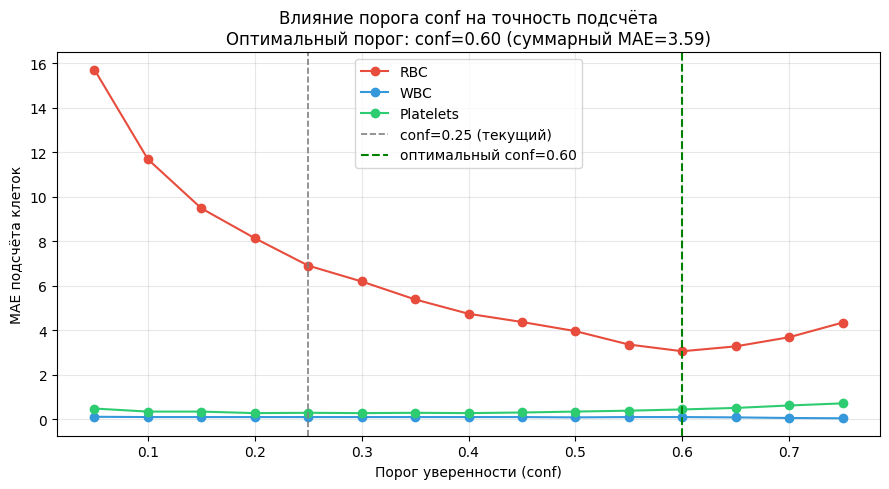

Выбранный порог conf=0.25: суммарный MAE = 7.29
Оптимальный порог conf=0.60: суммарный MAE = 3.59


In [17]:
val_images = list((YOLO_DIR / "images" / "val").glob("*.jpg"))
conf_thresholds = np.arange(0.05, 0.80, 0.05)

mae_by_conf = {cls: [] for cls in CLASSES}

for conf_thr in conf_thresholds:
    det_results = []
    for img_path in val_images:
        r = yolo_best.predict(str(img_path), conf=float(conf_thr), verbose=False)[0]
        counts = {cls: 0 for cls in CLASSES}
        if r.boxes is not None:
            for cls_id in r.boxes.cls.cpu().numpy().astype(int):
                counts[CLASS_IDX[cls_id]] += 1
        det_results.append({"filename": img_path.name, **counts})

    det_tmp = pd.DataFrame(det_results)
    ev_tmp = det_tmp.merge(gt_df, on="filename")
    for cls in CLASSES:
        if cls in ev_tmp.columns and cls + "_gt" in ev_tmp.columns:
            mae_by_conf[cls].append(mean_absolute_error(ev_tmp[cls + "_gt"], ev_tmp[cls]))
        else:
            mae_by_conf[cls].append(np.nan)

fig, ax = plt.subplots(figsize=(9, 5))
for cls in CLASSES:
    ax.plot(conf_thresholds, mae_by_conf[cls], marker="o", label=cls, color=CLASS_COLORS[cls])

ax.axvline(0.25, ls="--", c="grey", lw=1.2, label="conf=0.25 (текущий)")

total_mae = [sum(mae_by_conf[c][i] for c in CLASSES) for i in range(len(conf_thresholds))]
best_idx = int(np.nanargmin(total_mae))
best_conf = conf_thresholds[best_idx]
ax.axvline(best_conf, ls="--", c="green", lw=1.5, label=f"оптимальный conf={best_conf:.2f}")

ax.set_xlabel("Порог уверенности (conf)")
ax.set_ylabel("MAE подсчёта клеток")
ax.set_title("Влияние порога conf на точность подсчёта\n"
             f"Оптимальный порог: conf={best_conf:.2f} (суммарный MAE={total_mae[best_idx]:.2f})")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("yolo_conf_threshold_analysis.png", dpi=120)
plt.show()

idx_025 = int(np.argmin(np.abs(conf_thresholds - 0.25)))
print(f"Выбранный порог conf=0.25: суммарный MAE = {total_mae[idx_025]:.2f}")
print(f"Оптимальный порог conf={best_conf:.2f}: суммарный MAE = {total_mae[best_idx]:.2f}")


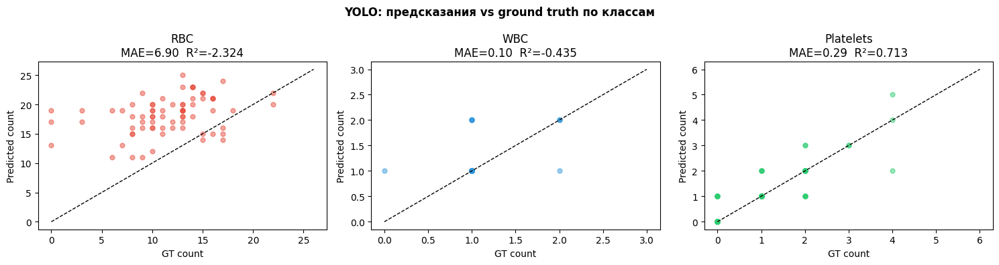

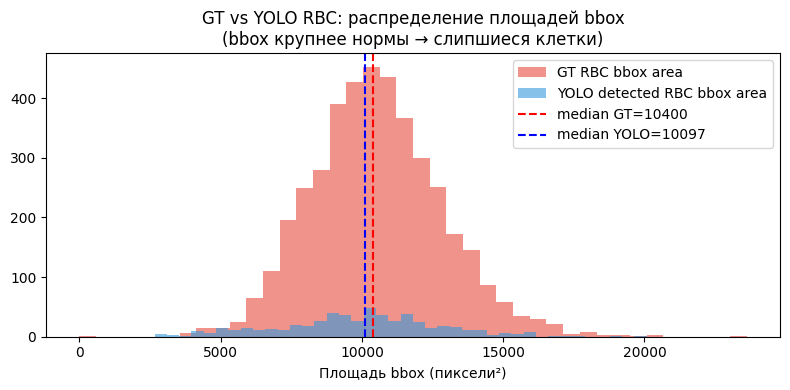

Детекций RBC с площадью > 2×median(GT): 0/546 (0.0%) — вероятные слипания
Вывод: YOLO занижает количество RBC из-за слипания клеток (cell clumping).
Решение: уменьшать iou/NMS, тюнить conf и рассмотреть instance segmentation.


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("YOLO: предсказания vs ground truth по классам", fontweight="bold")
for cls, ax in zip(CLASSES, axes):
    ax.scatter(eval_df[cls + "_gt"], eval_df[cls], alpha=0.5, color=CLASS_COLORS[cls], s=25)
    lim = max(eval_df[cls + "_gt"].max(), eval_df[cls].max()) + 1
    ax.plot([0, lim], [0, lim], "k--", lw=1)
    ax.set_xlabel("GT count")
    ax.set_ylabel("Predicted count")
    mae = mean_absolute_error(eval_df[cls + "_gt"], eval_df[cls])
    r2 = r2_score(eval_df[cls + "_gt"], eval_df[cls])
    ax.set_title(f"{cls}\nMAE={mae:.2f}  R²={r2:.3f}")
plt.tight_layout()
plt.savefig("yolo_per_class_scatter.png", dpi=120)
plt.show()

rbc_areas = []
for img_path in list((YOLO_DIR / "images" / "val").glob("*.jpg"))[:30]:
    r = yolo_best.predict(str(img_path), conf=0.25, verbose=False)[0]
    if r.boxes is None:
        continue
    for box, cls_id in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int)):
        if cls_id == 0:
            x1, y1, x2, y2 = box
            rbc_areas.append((x2 - x1) * (y2 - y1))

gt_rbc_areas = df[df["class"] == "RBC"]["area"].values

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(gt_rbc_areas, bins=40, alpha=0.6, label="GT RBC bbox area", color="#e74c3c")
ax.hist(rbc_areas, bins=40, alpha=0.6, label="YOLO detected RBC bbox area", color="#3498db")
ax.set_xlabel("Площадь bbox (пиксели²)")
ax.set_title("GT vs YOLO RBC: распределение площадей bbox\n(bbox крупнее нормы → слипшиеся клетки)")
ax.axvline(np.median(gt_rbc_areas), color="red", ls="--", lw=1.5,
           label=f"median GT={np.median(gt_rbc_areas):.0f}")
if len(rbc_areas) > 0:
    ax.axvline(np.median(rbc_areas), color="blue", ls="--", lw=1.5,
               label=f"median YOLO={np.median(rbc_areas):.0f}")
ax.legend()
plt.tight_layout()
plt.savefig("yolo_rbc_area_analysis.png", dpi=120)
plt.show()

n_large = sum(1 for a in rbc_areas if a > 2 * np.median(gt_rbc_areas))
print(f"Детекций RBC с площадью > 2×median(GT): {n_large}/{len(rbc_areas)} "
      f"({100 * n_large / max(len(rbc_areas), 1):.1f}%) — вероятные слипания")
print("Вывод: YOLO занижает количество RBC из-за слипания клеток (cell clumping).")
print("Решение: уменьшать iou/NMS, тюнить conf и рассмотреть instance segmentation.")


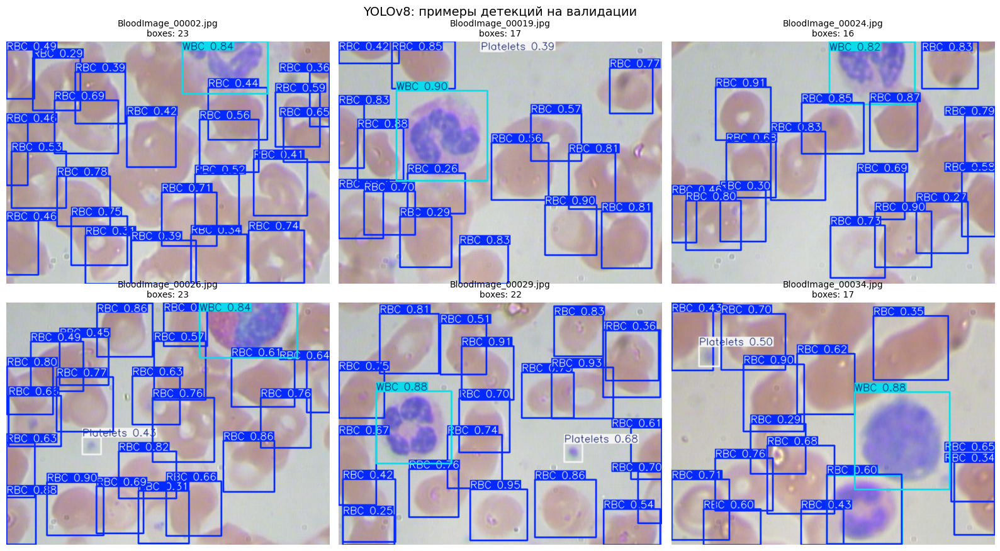

In [19]:
_val_imgs = sorted((YOLO_DIR / "images" / "val").glob("*.jpg"))
if not _val_imgs:
    raise FileNotFoundError(
        "Нет изображений в yolo_bccd/images/val — сначала выполните ячейки подготовки датасета YOLO и обучения."
    )

n_show = min(6, len(_val_imgs))
sample_imgs = _val_imgs[:n_show]  # можно заменить на random.sample(_val_imgs, n_show)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

for i, img_path in enumerate(sample_imgs):
    r = yolo_best.predict(str(img_path), conf=0.25, verbose=False)[0]
    n_det = len(r.boxes) if r.boxes is not None else 0
    annotated = r.plot()[..., ::-1]  # BGR -> RGB

    axes[i].imshow(annotated)
    axes[i].axis("off")
    axes[i].set_title(f"{img_path.name}\nboxes: {n_det}", fontsize=10)

for j in range(n_show, len(axes)):
    axes[j].axis("off")

fig.suptitle("YOLOv8: примеры детекций на валидации", fontsize=14)
fig.tight_layout()
fig.savefig("yolo_detection_examples.png", dpi=120)
plt.show()


## 4. Сравнение ResNet vs YOLO


In [20]:
print("\n Сравнение подходов к подсчёту клеток")
print("=" * 60)
print(f"{'Класс':12} | {'ResNet MAE':>12} | {'ResNet R²':>10} | {'YOLO MAE':>9} | {'YOLO R²':>8}")
print("-" * 60)

_, preds_reg, targets_reg = eval_epoch(model_reg, val_loader, criterion, DEVICE)
preds_reg_r = np.round(preds_reg).clip(0)

summary_rows = []
for i, cls in enumerate(CLASSES):
    mae_res = mean_absolute_error(targets_reg[:, i], preds_reg_r[:, i])
    r2_res  = r2_score(targets_reg[:, i], preds_reg_r[:, i])
    if cls in eval_df.columns and cls+"_gt" in eval_df.columns:
        mae_yo  = mean_absolute_error(eval_df[cls+"_gt"], eval_df[cls])
        r2_yo   = r2_score(eval_df[cls+"_gt"], eval_df[cls])
    else:
        mae_yo, r2_yo = float('nan'), float('nan')

    summary_rows.append({
        "class": cls,
        "resnet_mae": float(mae_res),
        "resnet_r2": float(r2_res),
        "yolo_mae": float(mae_yo),
        "yolo_r2": float(r2_yo),
    })
    print(f"{cls:12} | {mae_res:12.2f} | {r2_res:10.3f} | {mae_yo:9.2f} | {r2_yo:8.3f}")
print("=" * 60)

resnet_yolo_summary = pd.DataFrame(summary_rows)



 Сравнение подходов к подсчёту клеток
Класс        |   ResNet MAE |  ResNet R² |  YOLO MAE |  YOLO R²
------------------------------------------------------------
RBC          |         2.56 |      0.261 |      6.90 |   -2.324
WBC          |         0.04 |     -0.005 |      0.10 |   -0.435
Platelets    |         1.03 |     -0.252 |      0.29 |    0.713


## 5. OOD базовый (synthetic)


In [21]:
OOD_DIR = Path("ood_images")
OOD_DIR.mkdir(exist_ok=True)

def add_gaussian_noise(img_np, sigma=25):
    noise = np.random.normal(0, sigma, img_np.shape)
    return np.clip(img_np.astype(float) + noise, 0, 255).astype(np.uint8)

def add_gaussian_blur(img_np, radius=5):
    out = np.zeros_like(img_np)
    for c in range(3):
        out[:, :, c] = gaussian_filter(img_np[:, :, c], sigma=radius)
    return out

def add_salt_pepper(img_np, amount=0.05):
    out = img_np.copy()
    n = int(amount * img_np.size / 3)
    coords = [np.random.randint(0, d, n) for d in img_np.shape[:2]]
    out[coords[0], coords[1]] = 255
    coords = [np.random.randint(0, d, n) for d in img_np.shape[:2]]
    out[coords[0], coords[1]] = 0
    return out

all_img_paths = sorted(IMG_DIR.glob("*.jpg"))
np.random.seed(42)
perm = np.random.permutation(len(all_img_paths))

id_paths_ood_eval = [str(all_img_paths[i]) for i in perm[:300]]
ood_source_paths = [str(all_img_paths[i]) for i in perm[300:]]

ood_metadata = []
for img_path_str in ood_source_paths:
    img_path = Path(img_path_str)
    img_np = np.array(Image.open(img_path).convert("RGB"))
    for name, fn in [
        ("blur_mild", lambda x: add_gaussian_blur(x, 3)),
        ("blur_heavy", lambda x: add_gaussian_blur(x, 8)),
        ("noise_mild", lambda x: add_gaussian_noise(x, 20)),
        ("noise_heavy", lambda x: add_gaussian_noise(x, 60)),
        ("salt_pepper", lambda x: add_salt_pepper(x, 0.05)),
    ]:
        out_path = OOD_DIR / f"{img_path.stem}_{name}.jpg"
        Image.fromarray(fn(img_np)).save(out_path)
        ood_metadata.append({"path": str(out_path), "ood_type": name, "is_ood": True})

for p in ood_source_paths[:30]:
    ood_metadata.append({"path": p, "ood_type": "clean", "is_ood": False})

ood_df = pd.DataFrame(ood_metadata)
print(ood_df["ood_type"].value_counts())
print("Теперь ID и OOD-источники не пересекаются — AUROC честный.")


ood_type
blur_mild      64
blur_heavy     64
noise_mild     64
noise_heavy    64
salt_pepper    64
clean          30
Name: count, dtype: int64
Теперь ID и OOD-источники не пересекаются — AUROC честный.


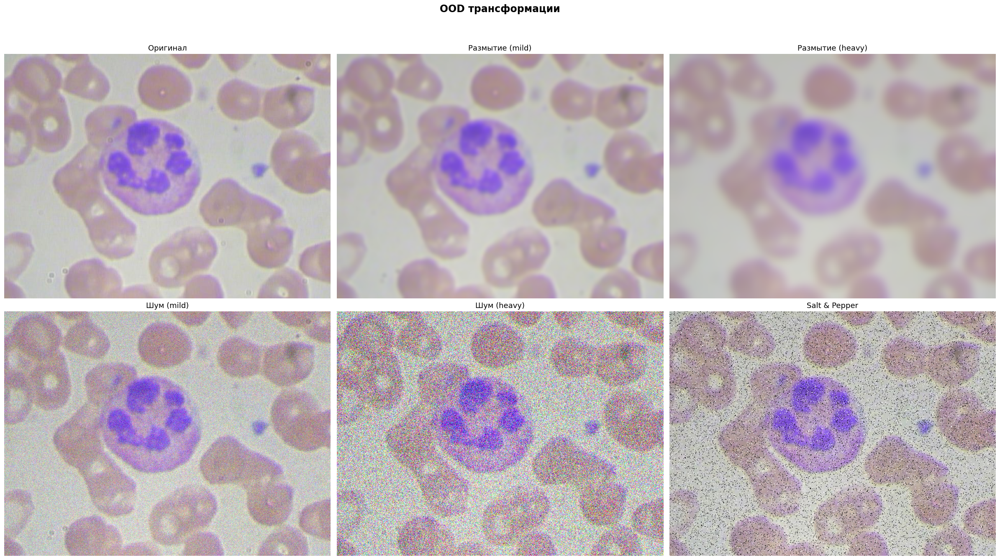

In [22]:
if not ood_source_paths:
    raise ValueError("Нет held-out изображений для OOD-визуализации")

orig_path = Path(ood_source_paths[0])
orig_np = np.array(Image.open(orig_path).convert("RGB"))

transformations = [
    ("Оригинал", orig_np),
    ("Размытие (mild)", add_gaussian_blur(orig_np, 3)),
    ("Размытие (heavy)", add_gaussian_blur(orig_np, 8)),
    ("Шум (mild)", add_gaussian_noise(orig_np, 20)),
    ("Шум (heavy)", add_gaussian_noise(orig_np, 60)),
    ("Salt & Pepper", add_salt_pepper(orig_np, 0.05)),
]

fig, axes = plt.subplots(2, 3, figsize=(24, 14))
axes = axes.flatten()
for ax, (title, img) in zip(axes, transformations):
    ax.imshow(img)
    ax.set_title(title, fontsize=13)
    ax.axis("off")

plt.suptitle("OOD трансформации", fontsize=17, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("ood_transformations.png", dpi=150)
plt.show()


In [23]:
feature_extractor = load_resnet50_imagenet()  # признаковый OOD-подход через Mahalanobis distance
feature_extractor.fc = nn.Identity()
feature_extractor = feature_extractor.to(DEVICE).eval()

preprocess = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

@torch.no_grad()
def extract_features(img_paths, model, device, batch_size=16):
    all_feats = []
    for i in range(0, len(img_paths), batch_size):
        batch = []
        for p in img_paths[i:i + batch_size]:
            try:
                img = Image.open(p).convert("RGB")
                batch.append(preprocess(img))
            except Exception:
                batch.append(torch.zeros(3, 224, 224))
        batch = torch.stack(batch).to(device)
        feats = model(batch).cpu().numpy()
        feats = np.nan_to_num(feats, nan=0.0, posinf=1e6, neginf=-1e6)
        all_feats.append(feats)
    return np.concatenate(all_feats)

id_feats = extract_features(id_paths_ood_eval, feature_extractor, DEVICE)
ood_paths = ood_df[ood_df["is_ood"] == True]["path"].tolist()
clean_paths = ood_df[ood_df["is_ood"] == False]["path"].tolist()

ood_feats = extract_features(ood_paths, feature_extractor, DEVICE)
clean_feats = extract_features(clean_paths, feature_extractor, DEVICE)

print(f"ID features (fit): {id_feats.shape}")
print(f"OOD features:      {ood_feats.shape}")
print(f"Clean features:    {clean_feats.shape}")


ID features (fit): (300, 2048)
OOD features:      (320, 2048)
Clean features:    (30, 2048)


Диагностика score: clean NaN/Inf=17, ood NaN/Inf=156
Фильтрация невалидных score: удалено 173 из 350
OOD Detection AUROC: 0.643
OOD Detection AUPR:  0.959
OOD AUROC: 0.643


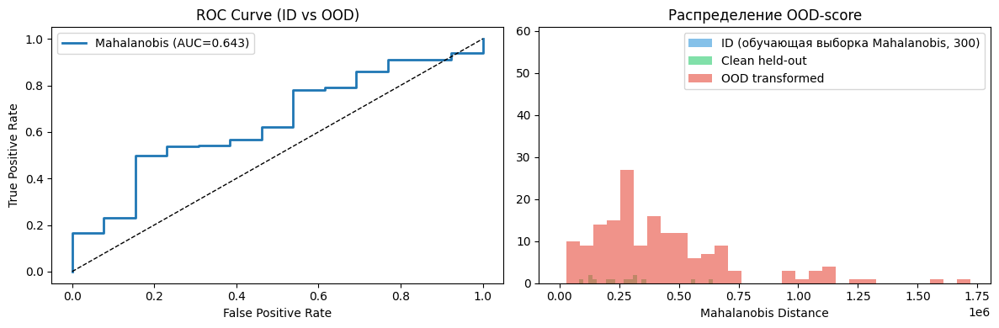

In [24]:
cov_model = EmpiricalCovariance().fit(id_feats)
mu = cov_model.location_
VI = np.linalg.pinv(cov_model.covariance_)

def maha_score(feats, mu, VI):
    diffs = np.nan_to_num(feats - mu, nan=0.0, posinf=1e6, neginf=-1e6)
    scores = np.sqrt(np.einsum('ij,jk,ik->i', diffs, VI, diffs))
    return np.nan_to_num(scores, nan=np.inf, posinf=np.inf, neginf=np.inf)

id_scores = maha_score(id_feats, mu, VI)
ood_scores = maha_score(ood_feats, mu, VI)
clean_scores = maha_score(clean_feats, mu, VI)

id_scores_plot = id_scores[np.isfinite(id_scores)]
clean_scores_plot = clean_scores[np.isfinite(clean_scores)]
ood_scores_plot = ood_scores[np.isfinite(ood_scores)]

print(
    f"Диагностика score: clean NaN/Inf={(~np.isfinite(clean_scores)).sum()}, "
    f"ood NaN/Inf={(~np.isfinite(ood_scores)).sum()}"
)

test_scores = np.concatenate([clean_scores, ood_scores])
test_labels = np.concatenate([np.zeros(len(clean_scores)), np.ones(len(ood_scores))])

valid = np.isfinite(test_scores)
if not np.all(valid):
    print(f"Фильтрация невалидных score: удалено {(~valid).sum()} из {len(test_scores)}")
test_scores = test_scores[valid]
test_labels = test_labels[valid]

if len(np.unique(test_labels)) < 2:
    auroc = float("nan")
    aupr = float("nan")
    fpr = np.array([0.0, 1.0])
    tpr = np.array([0.0, 1.0])
    print("OOD AUROC/AUPR недоступны: после фильтрации не осталось двух классов (ID и OOD).")
else:
    auroc = roc_auc_score(test_labels, test_scores)
    aupr = average_precision_score(test_labels, test_scores)
    fpr, tpr, _ = roc_curve(test_labels, test_scores)
    print(f"OOD Detection AUROC: {auroc:.3f}")
    print(f"OOD Detection AUPR:  {aupr:.3f}")

print(f"OOD AUROC: {auroc:.3f}" if np.isfinite(auroc) else "OOD AUROC: nan")

ood_auroc_latest = auroc

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot(fpr, tpr, lw=2, label=f"Mahalanobis (AUC={auroc:.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve (ID vs OOD)")
ax.legend()

ax = axes[1]
if id_scores_plot.size == 0:
    print("Предупреждение: нет конечных ID-score для гистограммы.")
if clean_scores_plot.size == 0:
    print("Предупреждение: нет конечных Clean-score для гистограммы.")
if ood_scores_plot.size == 0:
    print("Предупреждение: нет конечных OOD-score для гистограммы.")

if id_scores_plot.size == 0 and clean_scores_plot.size == 0 and ood_scores_plot.size == 0:
    ax.text(0.5, 0.5, "Нет конечных значений для гистограммы", ha='center', va='center')
    ax.set_axis_off()
else:
    if id_scores_plot.size > 0:
        ax.hist(id_scores_plot, bins=30, alpha=0.6, label="ID (обучающая выборка Mahalanobis, 300)", color="#3498db")
    if clean_scores_plot.size > 0:
        ax.hist(clean_scores_plot, bins=30, alpha=0.6, label="Clean held-out", color="#2ecc71")
    if ood_scores_plot.size > 0:
        ax.hist(ood_scores_plot, bins=30, alpha=0.6, label="OOD transformed", color="#e74c3c")
    ax.set_xlabel("Mahalanobis Distance")
    ax.set_title("Распределение OOD-score")
    ax.legend()

plt.tight_layout()
plt.show()



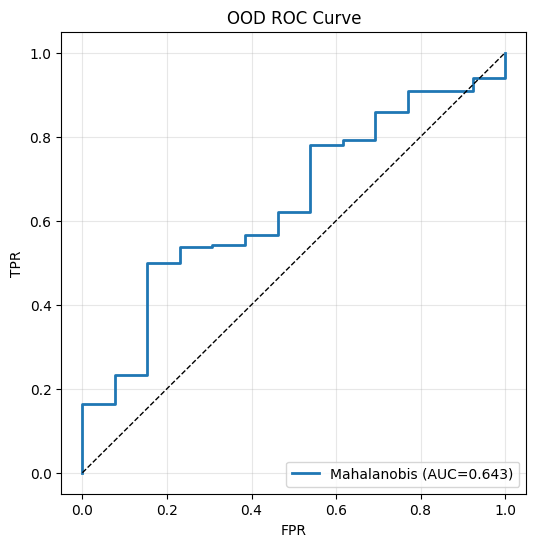

In [25]:
if len(test_scores) == 0 or len(np.unique(test_labels)) < 2:
    print("Недостаточно данных для отдельной OOD ROC-кривой.")
else:
    fpr_aug, tpr_aug, _ = roc_curve(test_labels, test_scores)
    plt.figure(figsize=(6, 6))
    plt.plot(fpr_aug, tpr_aug, lw=2, label=f"Mahalanobis (AUC={auroc:.3f})")
    plt.plot([0, 1], [0, 1], "k--", lw=1)
    plt.xlabel("FPR")
    plt.ylabel("TPR")
    plt.title("OOD ROC Curve")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.show()


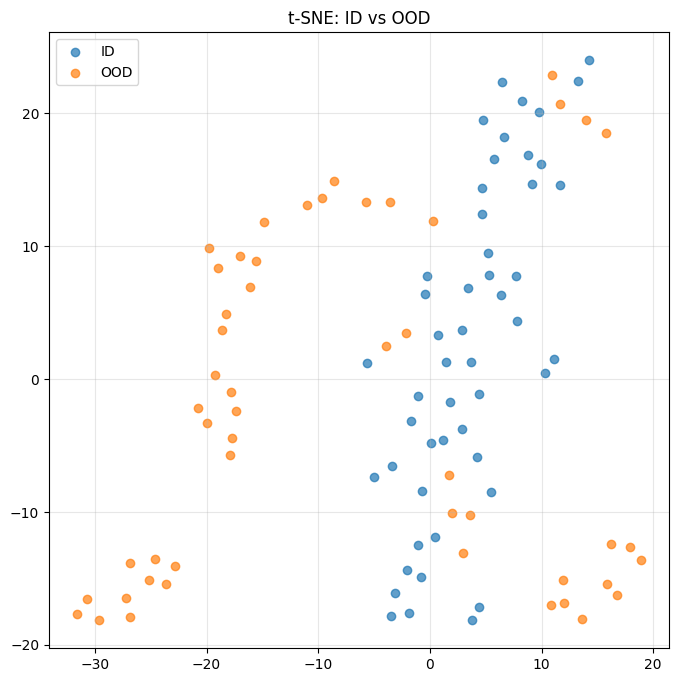

In [26]:
from sklearn.manifold import TSNE

features_tsne = []
labels_tsne = []

id_pool = list(id_paths_ood_eval)[:50]
ood_pool = list(ood_df[ood_df["is_ood"] == True]["path"].values)[:50]

for p in id_pool:
    if Path(p).is_file():
        features_tsne.append(extract_features([p], feature_extractor, DEVICE)[0])
        labels_tsne.append("ID")

for p in ood_pool:
    if Path(p).is_file():
        features_tsne.append(extract_features([p], feature_extractor, DEVICE)[0])
        labels_tsne.append("OOD")

if len(features_tsne) < 4 or len(set(labels_tsne)) < 2:
    print("Недостаточно данных для t-SNE: ID vs OOD")
else:
    features_tsne = np.array(features_tsne)
    emb = TSNE(n_components=2, random_state=42, perplexity=10).fit_transform(features_tsne)

    plt.figure(figsize=(8, 8))
    labels_tsne = np.array(labels_tsne)
    for lbl in ["ID", "OOD"]:
        idx = labels_tsne == lbl
        plt.scatter(emb[idx, 0], emb[idx, 1], label=lbl, alpha=0.7)

    plt.legend()
    plt.title("t-SNE: ID vs OOD")
    plt.grid(alpha=0.3)
    plt.show()


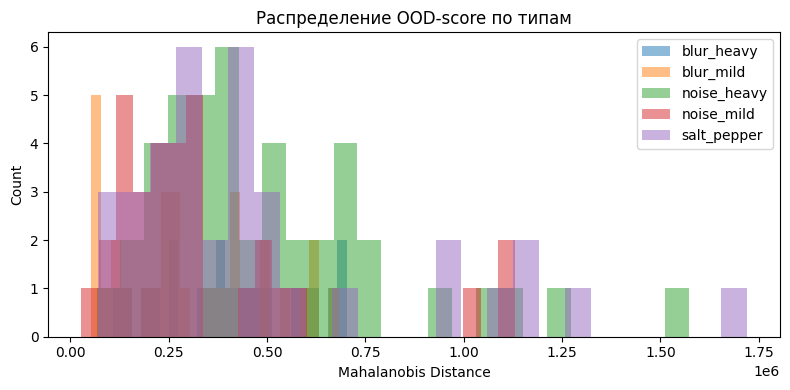

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
plotted_any = False
for ood_type in sorted(ood_df[ood_df["is_ood"]]["ood_type"].unique()):
    paths_t = ood_df[(ood_df["is_ood"]) & (ood_df["ood_type"] == ood_type)]["path"].tolist()
    feats_t = extract_features(paths_t, feature_extractor, DEVICE)
    scores_t = maha_score(feats_t, mu, VI)
    scores_t = scores_t[np.isfinite(scores_t)]
    if len(scores_t) == 0:
        print(f"skip {ood_type}")
        continue
    ax.hist(scores_t, bins=25, alpha=0.5, label=ood_type)
    plotted_any = True
ax.set_xlabel("Mahalanobis Distance")
ax.set_ylabel("Count")
ax.set_title("Распределение OOD-score по типам")
if not plotted_any:
    ax.text(0.5, 0.5, "Нет конечных значений OOD-score по типам", ha="center", va="center", transform=ax.transAxes)
else:
    ax.legend()
plt.tight_layout()
plt.show()


### ID vs OOD: визуальный пример

Слева — ID изображение BCCD, справа — синтетический OOD и realistic OOD (DIBaS/Malaria).

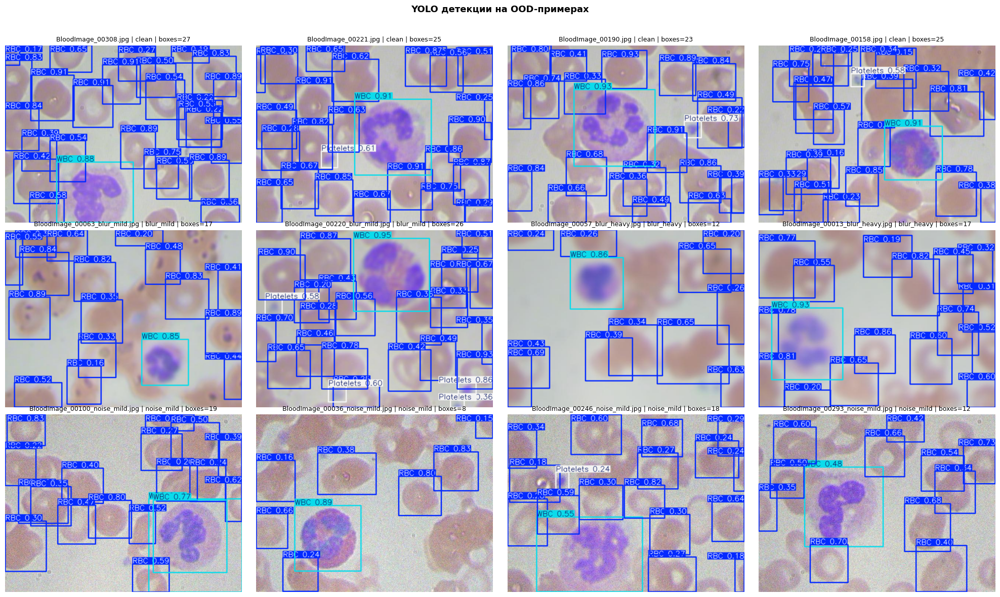

In [28]:
import random
from pathlib import Path

n_rows, n_cols = 3, 4
target_n = n_rows * n_cols
rng = random.Random(42)

records = []  # берём только synthetic OOD и clean из ood_metadata
if "ood_metadata" in globals():
    for rec in ood_metadata:
        try:
            p = Path(rec.get("path", ""))
            ood_type = str(rec.get("ood_type", ""))
            if p.exists() and (ood_type == "clean" or ood_type.startswith(("blur", "noise"))):
                records.append((p, ood_type))
        except Exception:
            continue

if not records:
    raise ValueError("Нет доступных изображений clean/blur/noise в ood_metadata для YOLO-визуализации.")

clean_records = [x for x in records if x[1] == "clean"]
blur_records = [x for x in records if x[1].startswith("blur")]
noise_records = [x for x in records if x[1].startswith("noise")]
fallback_pool = clean_records + blur_records + noise_records


def sample_records(items, n):
    if not items:
        return []
    if len(items) >= n:
        return rng.sample(items, n)
    return items + rng.choices(items, k=n - len(items))


selected = []
selected.extend(sample_records(clean_records, 4))
selected.extend(sample_records(blur_records, 4))
selected.extend(sample_records(noise_records, 4))

if len(selected) < target_n:  # добиваем до 12 случайными из fallback-пула
    selected.extend(rng.choices(fallback_pool, k=target_n - len(selected)))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = np.atleast_1d(axes).ravel()

for ax, (img_path, ood_type) in zip(axes, selected):
    r = yolo_best.predict(str(img_path), conf=0.15, verbose=False)[0]
    plotted = r.plot()[..., ::-1]  # BGR -> RGB
    n_boxes = len(r.boxes) if r.boxes is not None else 0
    ax.imshow(plotted)
    ax.set_title(f"{img_path.name} | {ood_type} | boxes={n_boxes}", fontsize=9)
    ax.axis("off")

plt.suptitle("YOLO детекции на OOD-примерах", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig("yolo_detection_examples.png", dpi=140)
plt.show()


## 6. OOD расширенный (external): Malaria + DIBaS

Внешний медицинский OOD в этой секции формируется из двух источников: `Malaria` и локального `DIBaS` из папки `archive` (с подготовкой в `ext_ood/dibas` без повторной тяжелой обработки).


In [29]:
import tensorflow_datasets as tfds

EXT_OOD_DIR = Path("ext_ood")
EXT_OOD_DIR.mkdir(exist_ok=True)

malaria_dir = EXT_OOD_DIR / "malaria"
malaria_dir.mkdir(exist_ok=True)

target_n = 400
existing = sorted(malaria_dir.glob("*.jpg"))
saved = len(existing)
print(f"[Malaria] already: {saved}")

if saved < target_n:
    ds = tfds.load("malaria", split="train", as_supervised=True)
    for img_tensor, _ in tfds.as_numpy(ds):
        if saved >= target_n:
            break
        out_path = malaria_dir / f"malaria_{saved:05d}.jpg"
        if out_path.exists():
            saved += 1
            continue
        Image.fromarray(img_tensor).convert("RGB").resize((224, 224)).save(out_path)
        saved += 1
        if saved % 25 == 0:
            print(f"[Malaria] saved {saved}/{target_n}")

print(f"[Malaria] done: {saved}")

# Локальный DIBaS из archive -> ext_ood/dibas (конвертация в RGB 224x224)
dibas_src_root = Path("archive")
dibas_dir = EXT_OOD_DIR / "dibas"
dibas_dir.mkdir(exist_ok=True)

dibas_target_n = 250
dibas_existing = sorted(dibas_dir.glob("*.jpg"))
dibas_saved = len(dibas_existing)
print(f"[DIBaS] already prepared: {dibas_saved}")

dibas_patterns = ("*.tif", "*.tiff", "*.png", "*.jpg", "*.jpeg", "*.bmp", "*.webp")
dibas_source_paths = []
if dibas_src_root.exists():
    for pattern in dibas_patterns:
        dibas_source_paths.extend(sorted(dibas_src_root.rglob(pattern)))
    dibas_source_paths = [p for p in dibas_source_paths if p.is_file() and p.stat().st_size > 0]
    dibas_source_paths = sorted(set(dibas_source_paths))

if dibas_saved < dibas_target_n and dibas_source_paths:
    remaining = dibas_target_n - dibas_saved
    for src_path in dibas_source_paths[dibas_saved:dibas_saved + remaining]:
        out_path = dibas_dir / f"dibas_{dibas_saved:05d}.jpg"
        if out_path.exists():
            dibas_saved += 1
            continue
        try:
            Image.open(src_path).convert("RGB").resize((224, 224)).save(out_path)
            dibas_saved += 1
            if dibas_saved % 50 == 0:
                print(f"[DIBaS] saved {dibas_saved}/{dibas_target_n}")
        except Exception:
            continue
elif not dibas_source_paths:
    print(f"[DIBaS] source files not found in {dibas_src_root.resolve()}")

print(f"[DIBaS] done: {dibas_saved}")
print("---- summary ----")
print("Malaria:", len(list(malaria_dir.glob('*.jpg'))))
print("DIBaS:", len(list(dibas_dir.glob('*.jpg'))))


[Malaria] already: 400
[Malaria] done: 400
[DIBaS] already prepared: 250
[DIBaS] done: 250
---- summary ----
Malaria: 400
DIBaS: 250


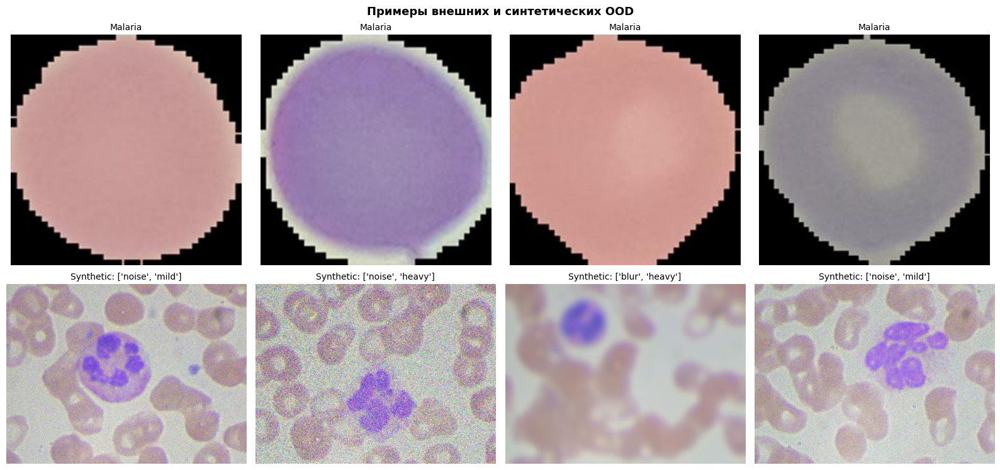

Malaria files: 400
Synthetic blur/noise files: 256


In [30]:
from random import sample

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

malaria_imgs = sorted((EXT_OOD_DIR / "malaria").glob("*.jpg"))  # 4 примера Malaria
malaria_pick = sample(malaria_imgs, k=min(4, len(malaria_imgs))) if malaria_imgs else []

synth_pool = [  # 4 примера синтетики (blur/noise)
    r["path"] for r in ood_metadata
    if r["is_ood"] and (r["ood_type"].startswith("blur") or r["ood_type"].startswith("noise"))
]
synth_pick = sample(synth_pool, k=min(4, len(synth_pool))) if synth_pool else []

for i in range(4):
    ax = axes[i]
    if i < len(malaria_pick):
        img = Image.open(malaria_pick[i]).convert("RGB")
        ax.imshow(img)
        ax.set_title("Malaria", fontsize=10)
    else:
        ax.text(0.5, 0.5, "нет изображения", ha='center', va='center')
    ax.axis("off")

for i in range(4):
    ax = axes[4 + i]
    if i < len(synth_pick):
        p = Path(synth_pick[i])
        img = Image.open(p).convert("RGB")
        ax.imshow(img)
        ax.set_title(f"Synthetic: {p.stem.split('_')[-2:]}", fontsize=10)
    else:
        ax.text(0.5, 0.5, "нет изображения", ha='center', va='center')
    ax.axis("off")

plt.suptitle("Примеры внешних и синтетических OOD", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Malaria files: {len(malaria_imgs)}")
print(f"Synthetic blur/noise files: {len(synth_pool)}")


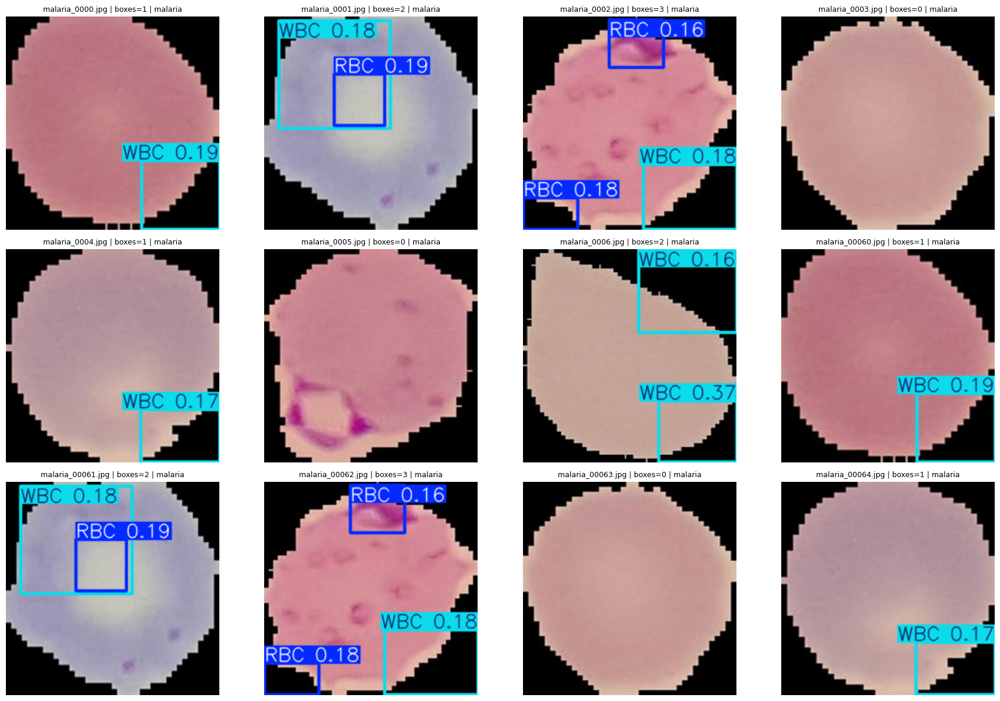

In [31]:
from pathlib import Path

malaria_dir = EXT_OOD_DIR / "malaria"
image_patterns = ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff", "*.webp"]
malaria_images = []
for pattern in image_patterns:
    malaria_images.extend(sorted(malaria_dir.glob(pattern)))

malaria_images = malaria_images[:12]

if len(malaria_images) == 0:
    print(f"Malaria images not found in {malaria_dir}")
else:
    n_rows, n_cols = 3, 4
    max_slots = n_rows * n_cols
    n_show = min(len(malaria_images), max_slots)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 12))
    axes = axes.flatten()

    for i in range(max_slots):
        ax = axes[i]
        if i < n_show:
            img_path = malaria_images[i]
            pred = yolo_best.predict(str(img_path), conf=0.15, verbose=False)
            result = pred[0]

            det_bgr = result.plot()
            det_rgb = det_bgr[..., ::-1]

            n_boxes = len(result.boxes) if result.boxes is not None else 0
            ax.imshow(det_rgb)
            ax.set_title(f"{img_path.name} | boxes={n_boxes} | malaria", fontsize=9)
            ax.axis("off")
        else:
            ax.axis("off")

    plt.tight_layout()
    plt.savefig("yolo_detection_malaria_examples.png", dpi=150, bbox_inches="tight")
    plt.show()


BCCD (ID)                    | mean=17.3 | std=0.0 | n=50
Malaria (заражённые клетки)  | mean=887730.4 | std=504789.6 | n=136
DIBaS (бактерии, external)   | mean=1131316.5 | std=999580.1 | n=138
Размытие (BCCD)              | mean=349598.8 | std=191163.0 | n=52
Шум (BCCD)                   | mean=439523.9 | std=304211.7 | n=76


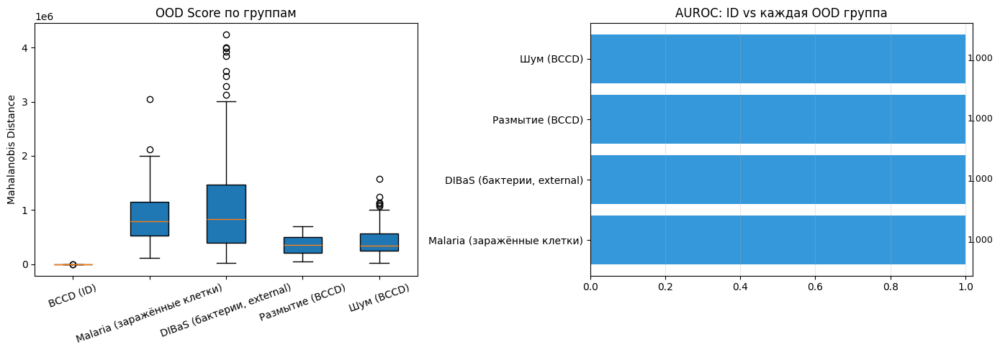

In [32]:
ext_ood_groups = {"BCCD (ID)": id_paths_ood_eval[:50]}

malaria_paths = [str(p) for p in malaria_dir.glob("*.jpg") if p.stat().st_size > 0]  # Malaria как внешний OOD
if malaria_paths:
    ext_ood_groups["Malaria (заражённые клетки)"] = malaria_paths

# DIBaS (внешний OOD, локально из archive)
dibas_dir = EXT_OOD_DIR / "dibas"
dibas_paths = [str(p) for p in dibas_dir.glob("*.jpg") if p.stat().st_size > 0]
if dibas_paths:
    ext_ood_groups["DIBaS (бактерии, external)"] = dibas_paths

blur_paths = [  # синтетические OOD-группы
    r["path"] for r in ood_metadata
    if r["ood_type"].startswith("blur") and r["is_ood"]
]
noise_paths = [
    r["path"] for r in ood_metadata
    if r["ood_type"].startswith("noise") and r["is_ood"]
]
if blur_paths:
    ext_ood_groups["Размытие (BCCD)"] = blur_paths
if noise_paths:
    ext_ood_groups["Шум (BCCD)"] = noise_paths

group_scores = {}
for name, paths in ext_ood_groups.items():
    valid_paths = [p for p in paths if Path(p).is_file()]
    if len(valid_paths) == 0:
        continue
    feats = extract_features(valid_paths, feature_extractor, DEVICE)
    scores = maha_score(feats, mu, VI)
    scores = scores[np.isfinite(scores)]
    if len(scores) == 0:
        print(f"{name:28} | нет валидных score (пропуск)")
        continue
    group_scores[name] = scores
    print(f"{name:28} | mean={scores.mean():.1f} | std={scores.std():.1f} | n={len(scores)}")

if "BCCD (ID)" not in group_scores or len(group_scores) < 2:
    print("Недостаточно групп для сравнения AUROC (нужен ID и минимум один OOD).")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    ax.boxplot([group_scores[k] for k in group_scores.keys()], labels=list(group_scores.keys()), patch_artist=True)
    ax.set_ylabel("Mahalanobis Distance")
    ax.set_title("OOD Score по группам")
    ax.tick_params(axis='x', rotation=20)

    ax = axes[1]
    auroc_scores, group_names = [], []
    id_sc = group_scores["BCCD (ID)"]
    for name, sc in group_scores.items():
        if name == "BCCD (ID)":
            continue
        labels = np.concatenate([np.zeros(len(id_sc)), np.ones(len(sc))])
        combined = np.concatenate([id_sc, sc])
        try:
            auc = roc_auc_score(labels, combined)
        except Exception:
            continue
        group_names.append(name)
        auroc_scores.append(auc)

    if len(group_names) == 0:
        ax.text(0.5, 0.5, "Нет валидных OOD-групп для AUROC", ha='center', va='center')
        ax.set_title("AUROC: ID vs каждая OOD группа")
        ax.set_xlim(0, 1)
    else:
        bars = ax.barh(group_names, auroc_scores, color="#3498db")
        for bar, val in zip(bars, auroc_scores):
            ax.text(val + 0.005, bar.get_y() + bar.get_height() / 2, f"{val:.3f}", va='center', fontsize=9)
        ax.set_xlim(0, 1.02)
        ax.set_title("AUROC: ID vs каждая OOD группа")
        ax.grid(True, axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()


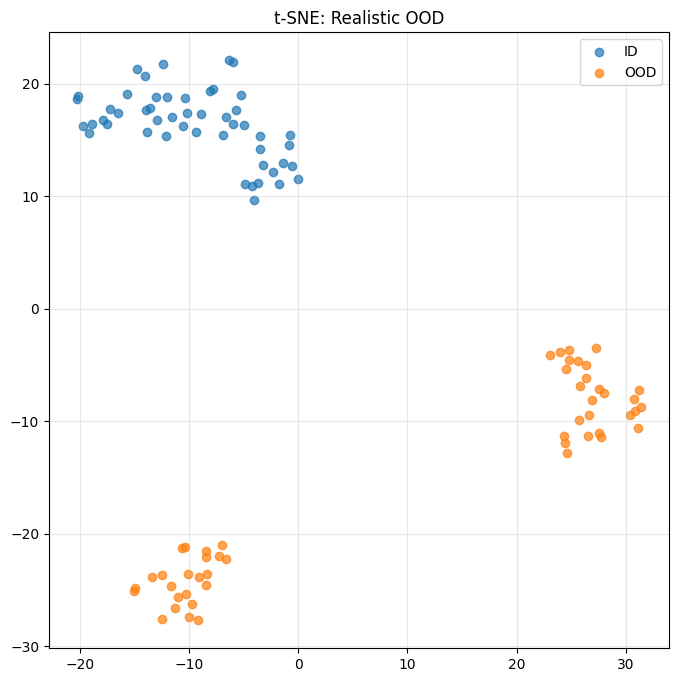

In [33]:
from sklearn.manifold import TSNE

real_id_paths = [p for p in id_paths_ood_eval[:50] if Path(p).is_file()]
real_ood_paths = []

if "dibas_dir" in globals() and Path(dibas_dir).exists():
    real_ood_paths.extend([str(p) for p in sorted(Path(dibas_dir).glob("*.jpg"))[:50]])
if len(real_ood_paths) == 0 and "malaria_dir" in globals() and Path(malaria_dir).exists():
    real_ood_paths.extend([str(p) for p in sorted(Path(malaria_dir).glob("*.jpg"))[:50]])

features_real = []
labels_real = []

for p in real_id_paths:
    features_real.append(extract_features([p], feature_extractor, DEVICE)[0])
    labels_real.append("ID")

for p in real_ood_paths:
    if Path(p).is_file():
        features_real.append(extract_features([p], feature_extractor, DEVICE)[0])
        labels_real.append("OOD")

if len(features_real) < 4 or len(set(labels_real)) < 2:
    print("Недостаточно данных для t-SNE: Realistic OOD")
else:
    features_real = np.array(features_real)
    emb_real = TSNE(n_components=2, perplexity=10, random_state=42).fit_transform(features_real)

    plt.figure(figsize=(8, 8))
    labels_real = np.array(labels_real)
    for lbl in ["ID", "OOD"]:
        idx = labels_real == lbl
        plt.scatter(emb_real[idx, 0], emb_real[idx, 1], label=lbl, alpha=0.7)

    plt.legend()
    plt.title("t-SNE: Realistic OOD")
    plt.grid(alpha=0.3)
    plt.show()


## 7. DIBaS


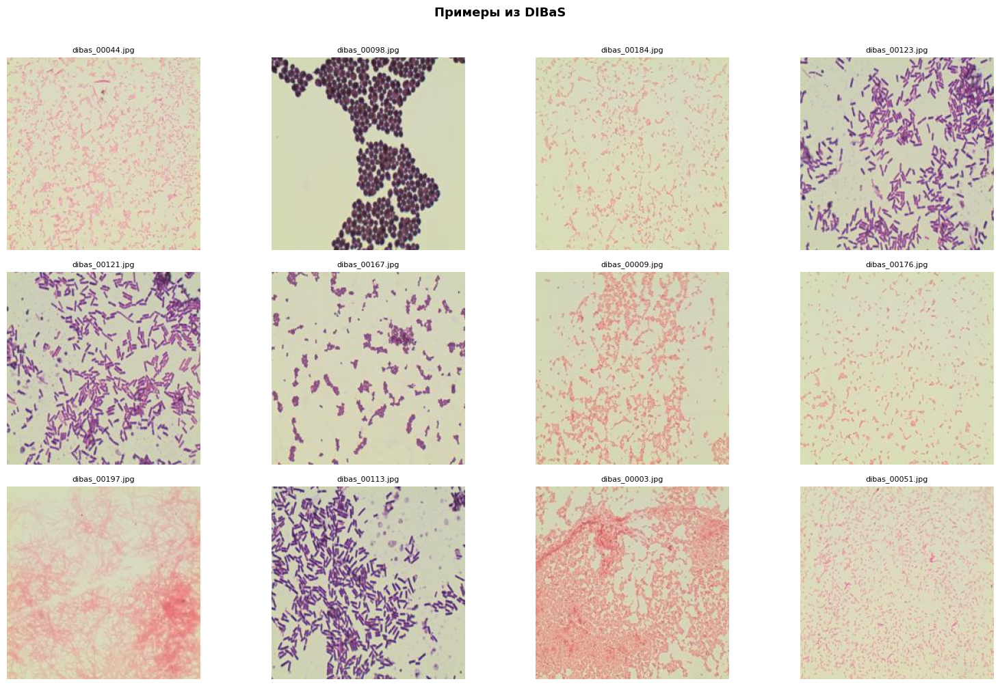

Показано 12 изображений из DIBaS (всего: 250)


In [34]:
import math
import random
from pathlib import Path

image_paths = sorted((Path("ext_ood") / "dibas").glob("*.jpg"))

if len(image_paths) == 0:
    print("DIBaS images not found in ext_ood/dibas")
else:
    rng = random.Random(42)
    picks = image_paths.copy()
    rng.shuffle(picks)

    n_show = min(12, max(8, len(picks)))
    picks = picks[:n_show]

    n_cols = 4
    n_rows = math.ceil(n_show / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.4 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for i, ax in enumerate(axes):
        if i < len(picks):
            img = Image.open(picks[i]).convert("RGB")
            ax.imshow(img)
            ax.set_title(picks[i].name, fontsize=8)
        else:
            ax.axis("off")
            continue
        ax.axis("off")

    plt.suptitle("Примеры из DIBaS", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()
    print(f"Показано {len(picks)} изображений из DIBaS (всего: {len(image_paths)})")

#### YOLO детекции на DIBaS

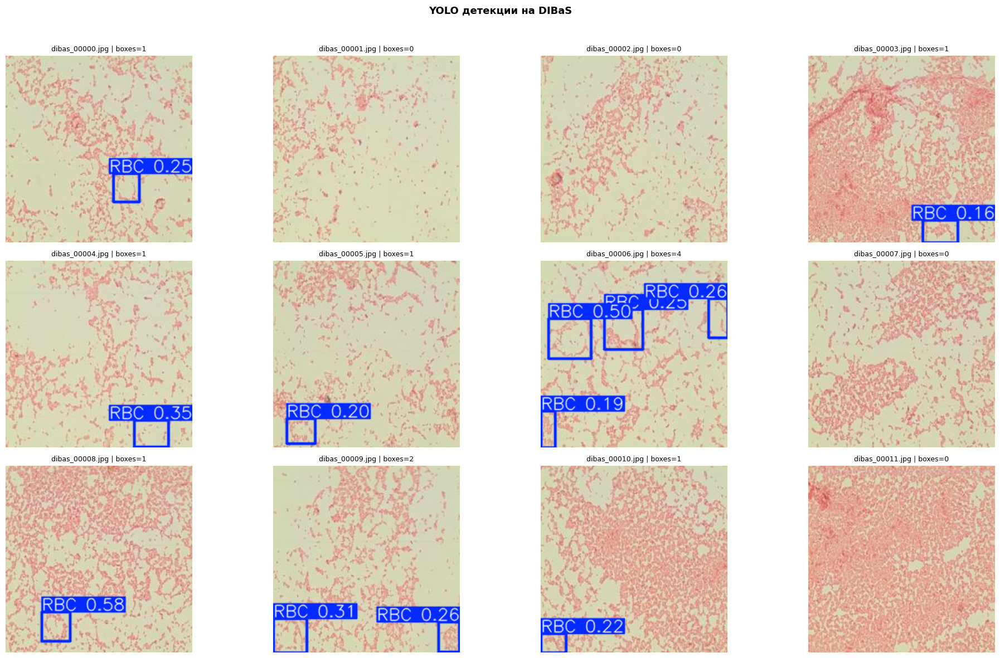

In [35]:
from pathlib import Path

dibas_images = sorted((Path("ext_ood") / "dibas").glob("*.jpg"))[:12]

if len(dibas_images) == 0:
    print("DIBaS images not found in ext_ood/dibas")
else:
    n_cols = 4
    n_rows = int(np.ceil(len(dibas_images) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
    axes = np.atleast_1d(axes).ravel()

    for i, ax in enumerate(axes):
        if i < len(dibas_images):
            img_path = dibas_images[i]
            r = yolo_best.predict(str(img_path), conf=0.15, verbose=False)[0]
            det_rgb = r.plot()[..., ::-1]
            n_boxes = len(r.boxes) if r.boxes is not None else 0
            ax.imshow(det_rgb)
            ax.set_title(f"{img_path.name} | boxes={n_boxes}", fontsize=9)
            ax.axis("off")
        else:
            ax.axis("off")

    plt.suptitle("YOLO детекции на DIBaS", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig("yolo_detection_dibas_examples.png", dpi=140)
    plt.show()

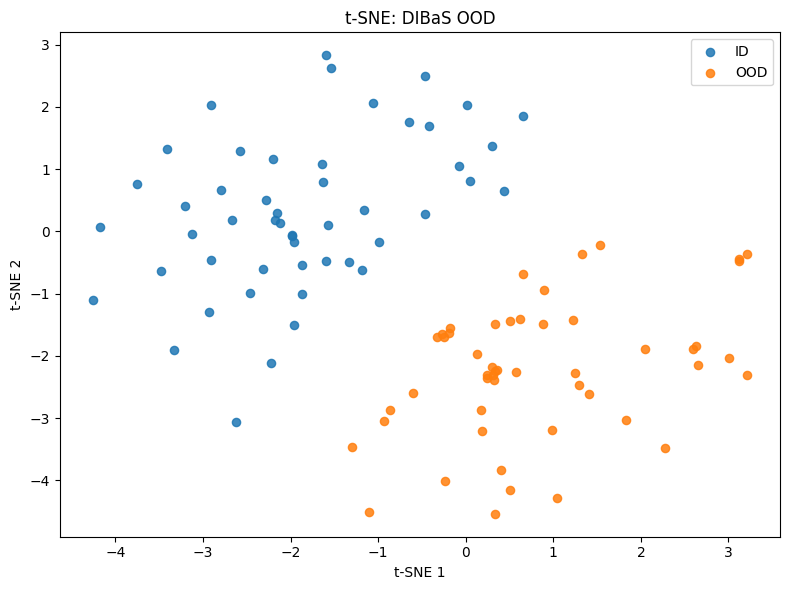

Построено t-SNE для ID(n=50) и DIBaS(n=50).
Сохранено: tsne_dibas_ood.png


In [37]:
# Отдельный t-SNE: ID vs DIBaS (finite-only, с ограничением выборки)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

max_id = 50
max_dibas = 50
rs = 42

# Берём заранее посчитанные признаки, если они есть в ноутбуке
id_feat_raw = globals().get('id_features', None)
dibas_feat_raw = globals().get('dibas_features', None)

if id_feat_raw is None:
    id_feat_raw = globals().get('id_feats', None)
if dibas_feat_raw is None:
    dibas_feat_raw = globals().get('dibas_feats', None)

if id_feat_raw is None or dibas_feat_raw is None:
    print('Пропуск t-SNE: не найдены признаки ID и/или DIBaS (id_features/dibas_features).')
else:
    id_feat = np.asarray(id_feat_raw)
    dibas_feat = np.asarray(dibas_feat_raw)

    # Приводим к 2D [N, D]
    if id_feat.ndim > 2:
        id_feat = id_feat.reshape(id_feat.shape[0], -1)
    if dibas_feat.ndim > 2:
        dibas_feat = dibas_feat.reshape(dibas_feat.shape[0], -1)

    if id_feat.ndim != 2 or dibas_feat.ndim != 2:
        print('Пропуск t-SNE: признаки должны быть двумерными массивами [N, D].')
    elif id_feat.size == 0 or dibas_feat.size == 0:
        print('Пропуск t-SNE: недостаточно данных (пустые признаки ID/DIBaS).')
    else:
        d_common = min(id_feat.shape[1], dibas_feat.shape[1])
        if d_common < 2:
            print('Пропуск t-SNE: слишком малая размерность признаков для визуализации.')
        else:
            id_feat = id_feat[:, :d_common]
            dibas_feat = dibas_feat[:, :d_common]

            id_mask = np.isfinite(id_feat).all(axis=1)
            dibas_mask = np.isfinite(dibas_feat).all(axis=1)
            id_fin = id_feat[id_mask]
            dibas_fin = dibas_feat[dibas_mask]

            if len(id_fin) < 5 or len(dibas_fin) < 5:
                print(f'Пропуск t-SNE: мало валидных признаков (ID={len(id_fin)}, DIBaS={len(dibas_fin)}).')
            else:
                rng = np.random.default_rng(rs)

                id_take = min(max_id, len(id_fin))
                dibas_take = min(max_dibas, len(dibas_fin))

                id_idx = rng.choice(len(id_fin), size=id_take, replace=False)
                dibas_idx = rng.choice(len(dibas_fin), size=dibas_take, replace=False)

                id_sel = id_fin[id_idx]
                dibas_sel = dibas_fin[dibas_idx]

                X = np.vstack([id_sel, dibas_sel])
                y = np.array(['ID'] * len(id_sel) + ['OOD'] * len(dibas_sel))

                # t-SNE чувствителен к масштабу признаков
                X_scaled = StandardScaler().fit_transform(X)

                n_samples = len(X_scaled)
                perplexity = min(30, max(5, n_samples // 3))

                tsne = TSNE(
                    n_components=2,
                    random_state=rs,
                    perplexity=perplexity,
                    init='pca',
                    learning_rate='auto'
                )
                emb = tsne.fit_transform(X_scaled)

                plt.figure(figsize=(8, 6))
                id_pts = (y == 'ID')
                ood_pts = (y == 'OOD')

                plt.scatter(emb[id_pts, 0], emb[id_pts, 1], s=35, alpha=0.85, label='ID', c='tab:blue')
                plt.scatter(emb[ood_pts, 0], emb[ood_pts, 1], s=35, alpha=0.85, label='OOD', c='tab:orange')

                plt.title('t-SNE: DIBaS OOD')
                plt.xlabel('t-SNE 1')
                plt.ylabel('t-SNE 2')
                plt.legend()
                plt.tight_layout()
                plt.savefig('tsne_dibas_ood.png', dpi=150)
                plt.show()

                print(f'Построено t-SNE для ID(n={len(id_sel)}) и DIBaS(n={len(dibas_sel)}).')
                print('Сохранено: tsne_dibas_ood.png')



#### Графики DIBaS

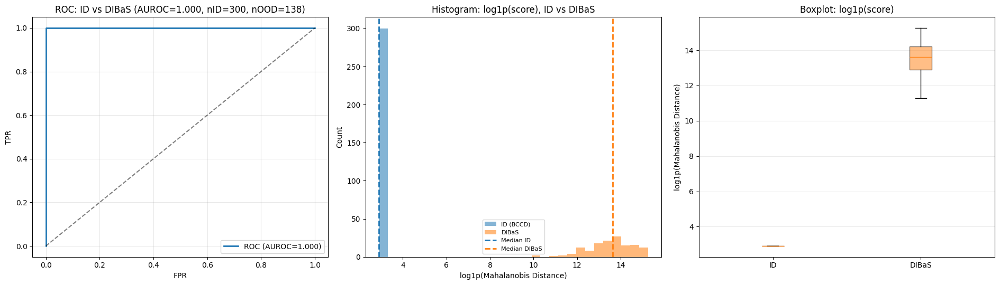

DIBaS visual summary:
ID:    median=17.2897, IQR=0.0003 (Q1=17.2896, Q3=17.2898), n=300
DIBaS: median=825863.8427, IQR=1072484.1381 (Q1=397267.2895, Q3=1469751.4275), n=138
Overlap proxy: доля DIBaS ниже 95-го перцентиля ID = 0.000%
Сохранено: ood_dibas_results_informative.png


In [38]:
from sklearn.metrics import roc_curve

id_scores_plot = np.array(dibas_metrics.get("id_scores", []), dtype=float) if "dibas_metrics" in globals() else np.array([])
dibas_scores_plot = np.array(dibas_metrics.get("dibas_scores", []), dtype=float) if "dibas_metrics" in globals() else np.array([])

if len(id_scores_plot) == 0 or len(dibas_scores_plot) == 0:
    print("Недостаточно данных для графиков DIBaS (нужны обе выборки: ID и DIBaS).")
else:
    id_scores_plot = id_scores_plot[np.isfinite(id_scores_plot)]
    dibas_scores_plot = dibas_scores_plot[np.isfinite(dibas_scores_plot)]

    if len(id_scores_plot) == 0 or len(dibas_scores_plot) == 0:
        print("После фильтрации не осталось корректных значений для графиков DIBaS.")
    else:
        id_log = np.log1p(np.clip(id_scores_plot, a_min=-0.999999, a_max=None))
        dibas_log = np.log1p(np.clip(dibas_scores_plot, a_min=-0.999999, a_max=None))

        fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

        y_true = np.concatenate([
            np.zeros(len(id_scores_plot), dtype=int),
            np.ones(len(dibas_scores_plot), dtype=int),
        ])
        y_score = np.concatenate([id_scores_plot, dibas_scores_plot])

        ax = axes[0]
        if len(np.unique(y_true)) == 2 and len(y_score) >= 4:
            fpr, tpr, _ = roc_curve(y_true, y_score)
            auroc_val = dibas_metrics.get("auroc", np.nan) if "dibas_metrics" in globals() else np.nan
            label = f"ROC (AUROC={auroc_val:.3f})" if np.isfinite(auroc_val) else "ROC"
            ax.plot(fpr, tpr, lw=2, label=label)
            ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
            ax.legend(loc="lower right")
        else:
            auroc_val = np.nan
            ax.text(0.5, 0.5, "Недостаточно данных для ROC", ha="center", va="center", transform=ax.transAxes)
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1)
        ax.set_title(
            f"ROC: ID vs DIBaS (AUROC={auroc_val:.3f}, nID={len(id_scores_plot)}, nOOD={len(dibas_scores_plot)})"
            if np.isfinite(auroc_val)
            else f"ROC: ID vs DIBaS (nID={len(id_scores_plot)}, nOOD={len(dibas_scores_plot)})"
        )
        ax.set_xlabel("FPR")
        ax.set_ylabel("TPR")
        ax.grid(alpha=0.3)

        ax = axes[1]
        bins = np.histogram_bin_edges(np.concatenate([id_log, dibas_log]), bins=30)
        ax.hist(id_log, bins=bins, alpha=0.55, label="ID (BCCD)", color="#1f77b4")
        ax.hist(dibas_log, bins=bins, alpha=0.55, label="DIBaS", color="#ff7f0e")
        id_med_log = np.median(id_log)
        dibas_med_log = np.median(dibas_log)
        ax.axvline(id_med_log, color="#1f77b4", linestyle="--", linewidth=2, label="Median ID")
        ax.axvline(dibas_med_log, color="#ff7f0e", linestyle="--", linewidth=2, label="Median DIBaS")
        ax.set_title("Histogram: log1p(score), ID vs DIBaS")
        ax.set_xlabel("log1p(Mahalanobis Distance)")
        ax.set_ylabel("Count")
        ax.legend(fontsize=8)

        ax = axes[2]
        bp = ax.boxplot([id_log, dibas_log], labels=["ID", "DIBaS"], patch_artist=True, showfliers=False)
        bp["boxes"][0].set_facecolor("#1f77b4")
        bp["boxes"][0].set_alpha(0.5)
        bp["boxes"][1].set_facecolor("#ff7f0e")
        bp["boxes"][1].set_alpha(0.5)
        ax.set_title("Boxplot: log1p(score)")
        ax.set_ylabel("log1p(Mahalanobis Distance)")
        ax.grid(axis="y", alpha=0.25)

        plt.tight_layout()
        fig.savefig("ood_dibas_results_informative.png", dpi=150, bbox_inches="tight")
        plt.show()

        id_median = np.median(id_scores_plot)
        dibas_median = np.median(dibas_scores_plot)
        id_q1, id_q3 = np.percentile(id_scores_plot, [25, 75])
        dibas_q1, dibas_q3 = np.percentile(dibas_scores_plot, [25, 75])
        id_iqr = id_q3 - id_q1
        dibas_iqr = dibas_q3 - dibas_q1
        id_p95 = np.percentile(id_scores_plot, 95)
        overlap_proxy = float(np.mean(dibas_scores_plot < id_p95))

        print("DIBaS visual summary:")
        print(f"ID:    median={id_median:.4f}, IQR={id_iqr:.4f} (Q1={id_q1:.4f}, Q3={id_q3:.4f}), n={len(id_scores_plot)}")
        print(f"DIBaS: median={dibas_median:.4f}, IQR={dibas_iqr:.4f} (Q1={dibas_q1:.4f}, Q3={dibas_q3:.4f}), n={len(dibas_scores_plot)}")
        print(f"Overlap proxy: доля DIBaS ниже 95-го перцентиля ID = {overlap_proxy:.3%}")
        print("Сохранено: ood_dibas_results_informative.png")



In [39]:
print("Итоги:")

print("\nResNet50:")
_, preds_reg_summary, targets_reg_summary = eval_epoch(model_reg, val_loader, criterion, DEVICE)
preds_reg_summary = np.round(preds_reg_summary).clip(0)
resnet_summary_df = pd.DataFrame([
    {
        "Класс": cls,
        "MAE": mean_absolute_error(targets_reg_summary[:, i], preds_reg_summary[:, i]),
        "R2": r2_score(targets_reg_summary[:, i], preds_reg_summary[:, i]),
    }
    for i, cls in enumerate(CLASSES)
])
print(resnet_summary_df)

print("\nYOLO:")
box_metrics_summary = None
if "val_metrics" in globals() and hasattr(val_metrics, "box"):
    box_metrics_summary = val_metrics.box
if "metrics" in globals() and hasattr(metrics, "box"):
    box_metrics_summary = metrics.box

if box_metrics_summary is not None:
    print("mAP50:", getattr(box_metrics_summary, "map50", float("nan")))
    print("mAP50-95:", getattr(box_metrics_summary, "map", float("nan")))
else:
    print("mAP50: недоступно")
    print("mAP50-95: недоступно")

final_ood_auroc = np.nan
if "ood_auroc_latest" in globals() and np.isfinite(ood_auroc_latest):
    final_ood_auroc = float(ood_auroc_latest)
elif "auroc_dibas" in globals() and np.isfinite(auroc_dibas):
    final_ood_auroc = float(auroc_dibas)
elif "auroc" in globals() and np.isfinite(auroc):
    final_ood_auroc = float(auroc)

print("\nOOD:")
if np.isfinite(final_ood_auroc):
    print("OOD AUROC:", final_ood_auroc)
else:
    print("OOD AUROC: недоступен")


Итоги:

ResNet50:
       Класс       MAE        R2
0        RBC  2.561644  0.260850
1        WBC  0.041096 -0.004587
2  Platelets  1.027397 -0.251833

YOLO:
mAP50: 0.8864530725745686
mAP50-95: 0.63159326282294

OOD:
OOD AUROC: 1.0
